# **Warhammer analysis**

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binomtest
from scipy.stats import pearsonr, spearmanr
from scipy import stats as sp_stats

### First of all we've got a .db file with 6 tables, but we need to work on python

1. Database connection

In [2]:
conn = sqlite3.connect("/Users/carlo_air_2021/Desktop/Magistrale/Data Management/Progetto analisi/warhammer_tournaments.db")

2. Check if the 6 tables in the .db file are still present.

In [3]:
query = "SELECT name FROM sqlite_master WHERE type='table';"
tables = pd.read_sql(query, conn)
tables

,name
0,sqlite_sequence
1,tournaments
2,prices
3,players
4,army_lists
5,army_list_units
6,matches


3. Load each table as a DataFrame

In [4]:
dfs = {}

for table in tables['name']:
    dfs[table] = pd.read_sql(f"SELECT * FROM {table}", conn)

In [5]:
df_sqlite_sequence = dfs['sqlite_sequence']
df_tournaments = dfs['tournaments']
df_prices = dfs['prices']
df_players = dfs['players']
df_army_lists = dfs['army_lists']
df_army_list_units = dfs['army_list_units']
df_matches = dfs['matches']


4. We would like that each column name is in lower so it will be easir do the analysis

In [6]:
df_sqlite_sequence.columns = df_sqlite_sequence.columns.str.lower()
df_tournaments.columns = df_tournaments.columns.str.lower()
df_prices.columns = df_prices.columns.str.lower()
df_players.columns = df_players.columns.str.lower()
df_army_lists.columns = df_army_lists.columns.str.lower()
df_army_list_units.columns = df_army_list_units.columns.str.lower()
df_matches.columns = df_matches.columns.str.lower()

## EDA - Exploratory Data Analysis 

### Tournament demographics (faction)

/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/3029348560.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_players, y='army', order=df_players['army'].value_counts().index, palette='Greens_r')


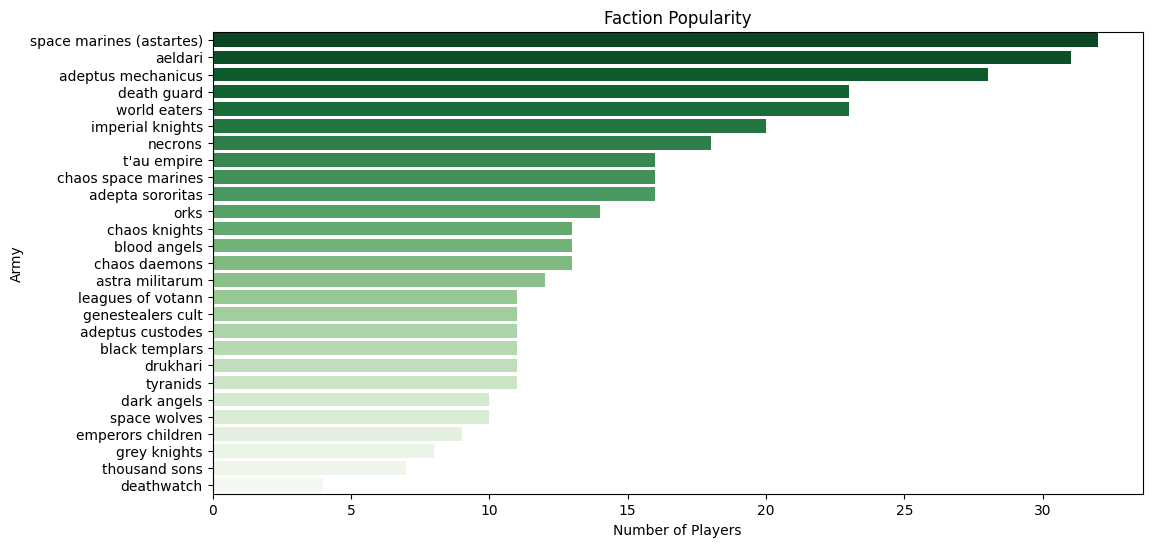

In [7]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df_players, y='army', order=df_players['army'].value_counts().index, palette='Greens_r')
plt.title('Faction Popularity')
plt.xlabel('Number of Players')
plt.ylabel('Army')
plt.show()

In [8]:
faction_table = df_players['army'].value_counts().reset_index()
faction_table.columns = ['Army', 'Player Count']

faction_table['Percentage (%)'] = (faction_table['Player Count'] / faction_table['Player Count'].sum() * 100).round(2)

print("--- Faction Popularity Table ---")
display(faction_table)

--- Faction Popularity Table ---


,Army,Player Count,Percentage (%)
0,space marines (astartes),32,7.96
1,aeldari,31,7.71
2,adeptus mechanicus,28,6.97
3,death guard,23,5.72
4,world eaters,23,5.72
5,imperial knights,20,4.98
6,necrons,18,4.48
7,t'au empire,16,3.98
8,chaos space marines,16,3.98
9,adepta sororitas,16,3.98


In [9]:
mean_faction_table = faction_table['Player Count'].mean()
median_faction_table = faction_table['Player Count'].median()

print("The mean faction player count is:", mean_faction_table.round(2))
print("The median faction player count is:", median_faction_table.round(2))

The mean faction player count is: 14.89
The median faction player count is: 13.0


### Player performace (win rate)

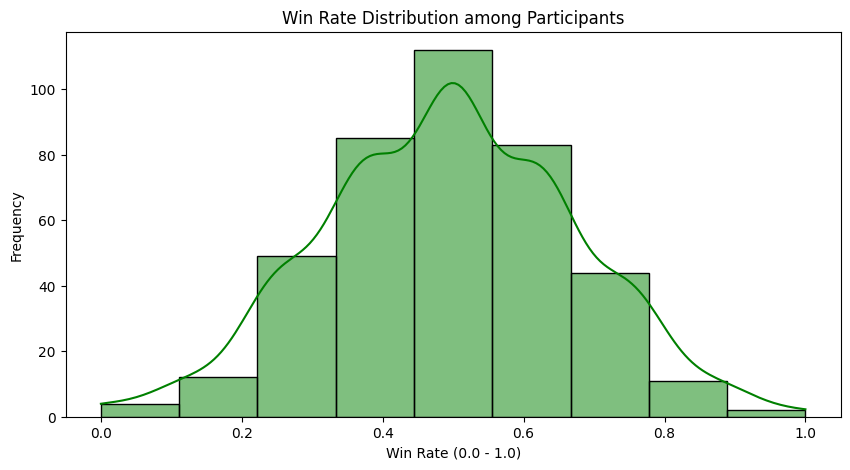

In [10]:
df_players['total_matches'] = df_players['wins'] + df_players['losses'] + df_players['ties']
df_players['win_rate'] = df_players['wins'] / df_players['total_matches']

plt.figure(figsize=(10, 5))
sns.histplot(df_players['win_rate'], bins=9, kde=True, color='green')
plt.title('Win Rate Distribution among Participants')
plt.xlabel('Win Rate (0.0 - 1.0)')
plt.ylabel('Frequency')

plt.savefig('Win_rate_Distribution_among_Participants.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
df_players_WR_mean = df_players['win_rate'].mean()
df_players_WR_median = df_players['win_rate'].median()

print("The mean win rate is:", df_players_WR_mean.round(2))
print("The median win rate is:", df_players_WR_median.round(2))

The mean win rate is: 0.49
The median win rate is: 0.5


### Economic analysis (price for army)

Median players per faction: 13.0


/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/2773781799.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


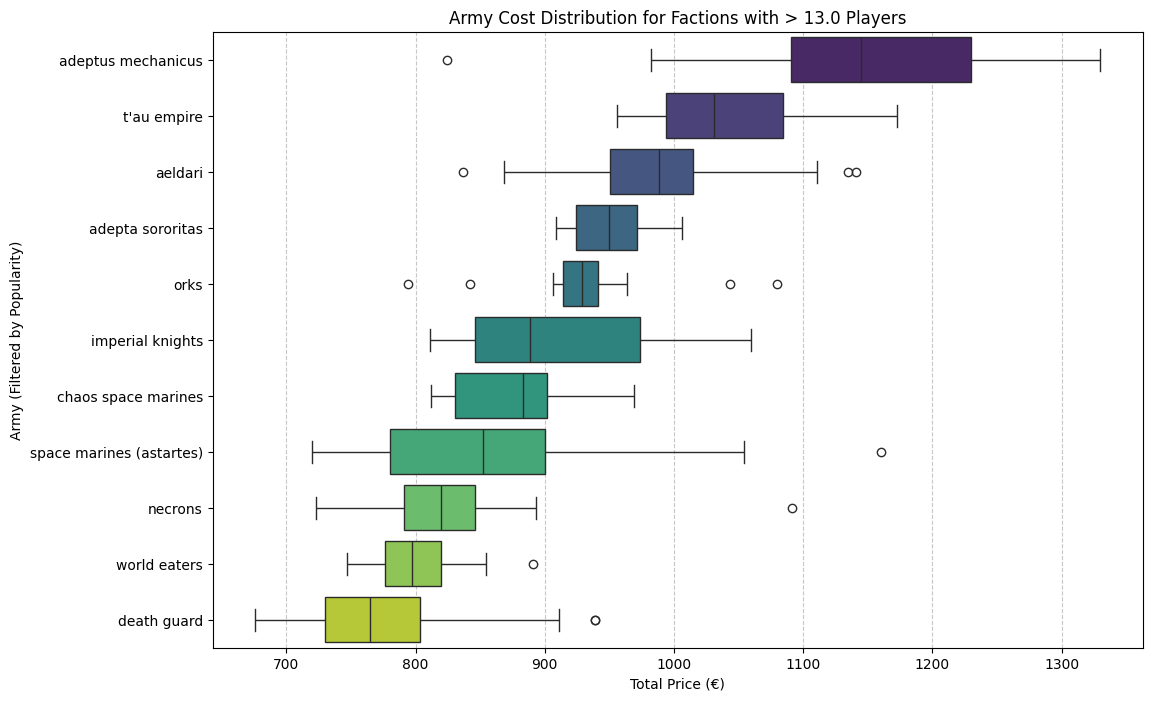

In [12]:
df_cost_player = df_army_list_units.groupby('id_player')['total_price'].sum().reset_index()
df_economy = df_players[['id_player', 'army']].merge(df_cost_player, on='id_player')

faction_counts = df_economy['army'].value_counts()
print(f"Median players per faction: {faction_counts.median()}")

popular_factions = faction_counts[faction_counts > faction_counts.median()].index.tolist()
df_economy_filtered = df_economy[df_economy['army'].isin(popular_factions)]

plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df_economy_filtered, 
    x='total_price', 
    y='army', 
    order=df_economy_filtered.groupby('army')['total_price'].median().sort_values(ascending=False).index,
    palette='viridis'
)

plt.title(f'Army Cost Distribution for Factions with > {faction_counts.median()} Players')
plt.xlabel('Total Price (€)')
plt.ylabel('Army (Filtered by Popularity)')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.savefig('Army_Cost_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

### Economic analysis (price for  unit and their points)

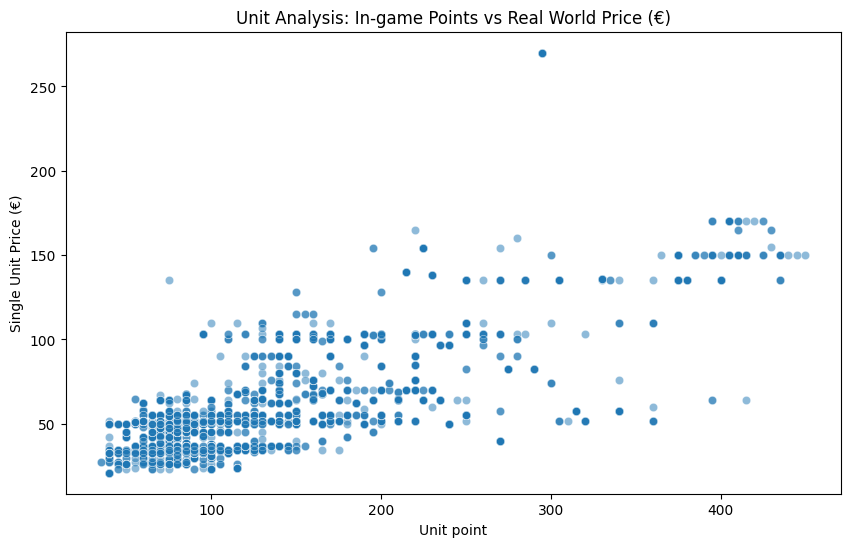

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_army_list_units, x='points', y='single_price', alpha=0.5)
plt.title('Unit Analysis: In-game Points vs Real World Price (€)')
plt.xlabel('Unit point')
plt.ylabel('Single Unit Price (€)')
plt.show()

Pearson Correlation (Linear): 0.755 (p-value: 0.000e+00)
Spearman Correlation (Non-linear): 0.643 (p-value: 0.000e+00)


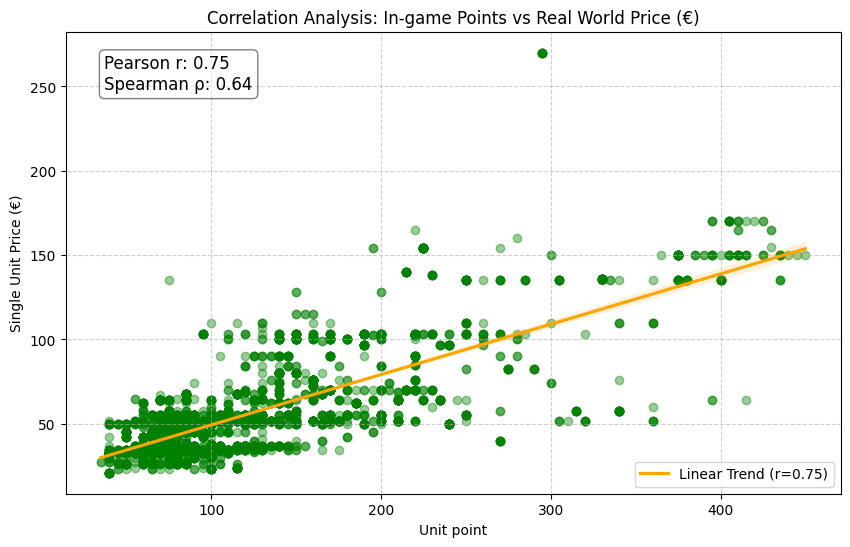

In [14]:
df_corr_units = df_army_list_units[['points', 'single_price']].dropna()


p_corr, p_pval = pearsonr(df_corr_units['points'], df_corr_units['single_price'])
s_corr, s_pval = spearmanr(df_corr_units['points'], df_corr_units['single_price'])

print(f"Pearson Correlation (Linear): {p_corr:.3f} (p-value: {p_pval:.3e})")
print(f"Spearman Correlation (Non-linear): {s_corr:.3f} (p-value: {s_pval:.3e})")


plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_corr_units, 
    x='points', 
    y='single_price', 
    scatter_kws={'alpha':0.4, 'color': 'green'}, 
    line_kws={'color': 'orange', 'label': f'Linear Trend (r={p_corr:.2f})'}
)
stats_text = f"Pearson r: {p_corr:.2f}\nSpearman ρ: {s_corr:.2f}"
plt.gca().text(0.05, 0.95, stats_text, transform=plt.gca().transAxes, 
               fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

plt.title('Correlation Analysis: In-game Points vs Real World Price (€)')
plt.xlabel('Unit point')
plt.ylabel('Single Unit Price (€)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.savefig('Correlation_Analysis_Points_vs_Price.png', dpi=300, bbox_inches='tight')
plt.show()

### Score differential

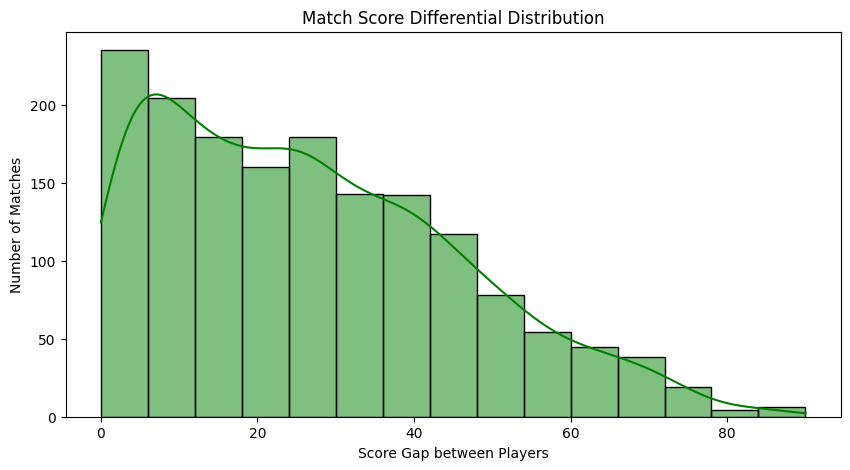

Global average score per player per match: 70.55


In [15]:
df_matches['score_diff'] = abs(df_matches['score_player1'] - df_matches['score_player2'])

plt.figure(figsize=(10, 5))
sns.histplot(df_matches['score_diff'], bins=15, color='green', kde=True)
plt.title('Match Score Differential Distribution')
plt.xlabel('Score Gap between Players')
plt.ylabel('Number of Matches')
plt.savefig('Match_Score_Differential_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

avg_score = (df_matches['score_player1'].mean() + df_matches['score_player2'].mean()) / 2
print(f"Global average score per player per match: {avg_score:.2f}")

## 1. Economic analysis

### 1.1 Is the meta pay-to-win?

More specifically we would like to know if there is any kind of correlation between the cost of an army and the final rank of a player / number of victory

In [16]:
# PREPARATION OF DATA

# 1. We're going to calculate the total cost for each player
player_costs = df_army_list_units.groupby('id_player')['total_price'].sum().reset_index()
player_costs.columns = ['id_player', 'total_army_cost']

# 2. We're going to merge out data with the player data (rank, wins)
df_analysis = df_players.merge(player_costs, on='id_player', how='left')

# 3. We're going to remove any players without cost data
df_analysis = df_analysis.dropna(subset=['total_army_cost'])

print(f"Dataset ready: {len(df_analysis)} players with full information")
print(f"\nDescriptive statistics army costs:")
print(df_analysis['total_army_cost'].describe())

Dataset ready: 402 players with full information

Descriptive statistics army costs:
count     402.000000
mean      927.010199
std       127.071880
min       581.000000
25%       832.750000
50%       922.750000
75%       999.812500
max      1330.000000
Name: total_army_cost, dtype: float64


In [17]:
# CORRELATION ANALYSIS: COST vs RANK 

print("\n" + "="*41)
print("CORRELATION: TOTAL COST vs RANK POSITION")
print("="*41)

corr_rank_pearson, p_value_rank_pearson = stats.pearsonr(
    df_analysis['total_army_cost'], 
    df_analysis['rank']
)

corr_rank_spearman, p_value_rank_spearman = stats.spearmanr(
    df_analysis['total_army_cost'], 
    df_analysis['rank']
)

print(f"\nPearson correlation: {corr_rank_pearson:.4f} (p-value: {p_value_rank_pearson:.4f})")
print(f"Spearman correlation: {corr_rank_spearman:.4f} (p-value: {p_value_rank_spearman:.4f})")

if p_value_rank_spearman < 0.05:
    print(f"\n✓ SIGNIFICANT CORRELATION (p < 0.05)")
    if corr_rank_spearman < 0:
        print("  > Higher cost are associated with better ranks (lower values)")
    else:
        print("  > Higher costs are associated with worse ranks (higher values)")
else:
    print(f"\n Correlation is NOT significant (p ≥ 0.05)")


CORRELATION: TOTAL COST vs RANK POSITION

Pearson correlation: -0.1600 (p-value: 0.0013)
Spearman correlation: -0.1393 (p-value: 0.0052)

✓ SIGNIFICANT CORRELATION (p < 0.05)
  > Higher cost are associated with better ranks (lower values)


In [18]:
# CORRELATION ANALYSIS: COST vs WINS
    
print("\n" + "="*42)
print("CORRELATION: TOTAL COST vs NUMBER OF WINS")
print("="*42)

corr_wins_pearson, p_value_wins_pearson = stats.pearsonr(
    df_analysis['total_army_cost'], 
    df_analysis['wins']
)

corr_wins_spearman, p_value_wins_spearman = stats.spearmanr(
    df_analysis['total_army_cost'], 
    df_analysis['wins']
)

print(f"\nPearson correlation: {corr_wins_pearson:.4f} (p-value: {p_value_wins_pearson:.4f})")
print(f"Spearman correlation: {corr_wins_spearman:.4f} (p-value: {p_value_wins_spearman:.4f})")

if p_value_wins_spearman < 0.05:
    print(f"\n✓ SIGNIFICANT CORRELATION (p < 0.05)")
    if corr_wins_spearman > 0:
        print("  > Higher costs are associated with MORE WINS")
    else:
        print("  > Higher costs are associated with FEWER WINS")
else:
    print(f"\n Correlation is NOT significant (p ≥ 0.05)")


CORRELATION: TOTAL COST vs NUMBER OF WINS

Pearson correlation: 0.1308 (p-value: 0.0086)
Spearman correlation: 0.1075 (p-value: 0.0312)

✓ SIGNIFICANT CORRELATION (p < 0.05)
  > Higher costs are associated with MORE WINS


The correlation with the ranks and the wins is significant based on the p-values. For these reasons, we can proceed with more advanced analyses.

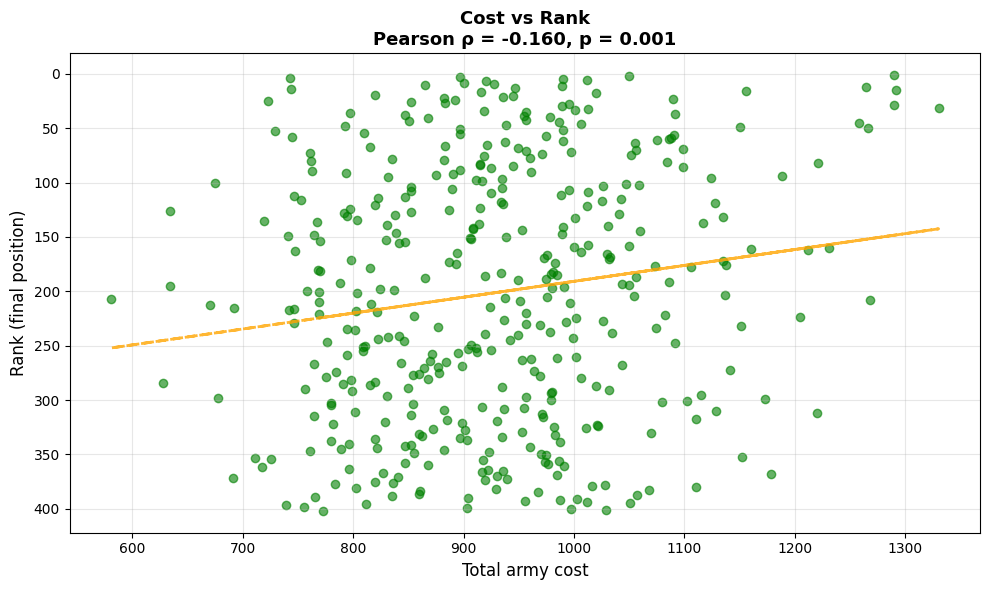

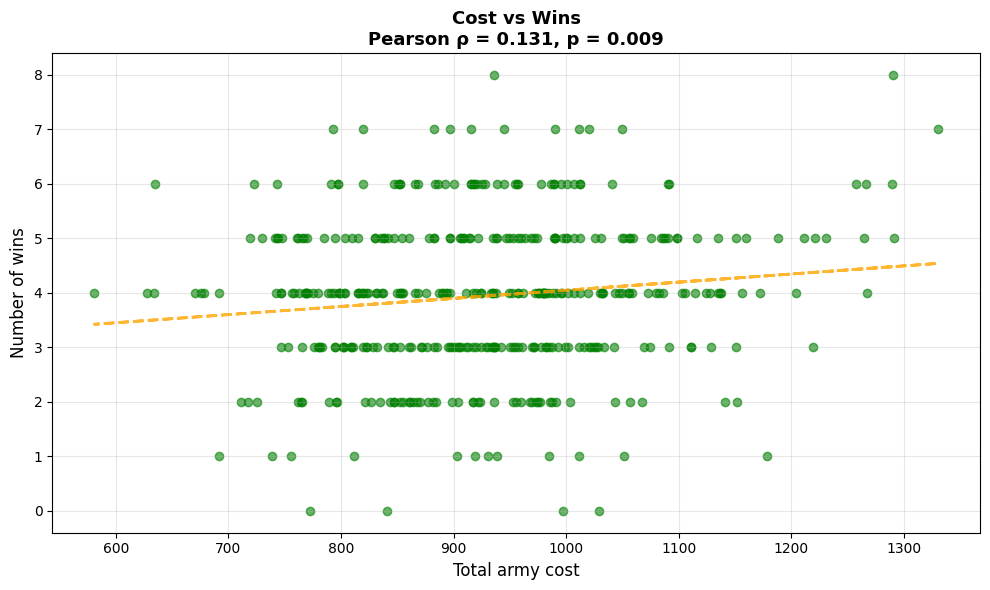

In [19]:
# FIRST GRAPH: COST VS RANK
plt.figure(figsize=(10, 6))
plt.scatter(df_analysis['total_army_cost'], df_analysis['rank'], alpha=0.6, color='green')
plt.xlabel('Total army cost', fontsize=12)
plt.ylabel('Rank (final position)', fontsize=12)
plt.title(f'Cost vs Rank\nPearson ρ = {corr_rank_pearson:.3f}, p = {p_value_rank_pearson:.3f}', 
          fontsize=13, fontweight='bold')
plt.grid(alpha=0.3)
plt.gca().invert_yaxis()  

# Trendline per rank
z1 = np.polyfit(df_analysis['total_army_cost'], df_analysis['rank'], 1)
p1 = np.poly1d(z1)
plt.plot(df_analysis['total_army_cost'], p1(df_analysis['total_army_cost']), 
         color='orange', linestyle='--', alpha=0.8, linewidth=2)

plt.tight_layout()
plt.savefig('Cost_vs_Rank.png', dpi=300)
plt.show()

# SECOND GRAPH: COST VS WINS
plt.figure(figsize=(10, 6))
plt.scatter(df_analysis['total_army_cost'], df_analysis['wins'], alpha=0.6, color='green')
plt.xlabel('Total army cost', fontsize=12)
plt.ylabel('Number of wins', fontsize=12)
plt.title(f'Cost vs Wins\nPearson ρ = {corr_wins_pearson:.3f}, p = {p_value_wins_pearson:.3f}', 
          fontsize=13, fontweight='bold')
plt.grid(alpha=0.3)

# Trendline per wins
z2 = np.polyfit(df_analysis['total_army_cost'], df_analysis['wins'], 1)
p2 = np.poly1d(z2)
plt.plot(df_analysis['total_army_cost'], p2(df_analysis['total_army_cost']), 
         color='orange', linestyle='--', alpha=0.8, linewidth=2)

plt.tight_layout()
plt.savefig('Cost_vs_Wins.png', dpi=300)
plt.show()

### 1.2 What is the mean cost to be competitive?

In this section, we aim to calculate the average price of the top 25 players and the bottom 25 players. Our goal is to understand whether there is a minimum army value required to be competitive.

In [20]:
# 1. We need to order by the rank
df_analysis = df_analysis.sort_values('rank').reset_index(drop=True)

n_players = len(df_analysis)

# 2. Select the: Top 25 and Bottom 25
top_25 = df_analysis.nsmallest(25, 'rank')  # The lowest rank are the best (1, 2, 3, ...)
bottom_25 = df_analysis.nlargest(25, 'rank')  # The highest rank are the worst (n, n-1, n-2, ...)

# Statistics Top 25
top_25_stats = {
    'mean': top_25['total_army_cost'].mean(),
    'median': top_25['total_army_cost'].median(),
    'std': top_25['total_army_cost'].std(),
    'min': top_25['total_army_cost'].min(),
    'max': top_25['total_army_cost'].max()
}

# Statistics Bottom 25
bottom_25_stats = {
    'mean': bottom_25['total_army_cost'].mean(),
    'median': bottom_25['total_army_cost'].median(),
    'std': bottom_25['total_army_cost'].std(),
    'min': bottom_25['total_army_cost'].min(),
    'max': bottom_25['total_army_cost'].max()
}

In [21]:
# STATISTICS OUTPUT 
print(f"\nTotal players analyzed: {n_players}")
print("\n" + "-"*60)
print("TOP 25 PLAYERS (Rank 1-25)")
print("-"*60)
print(f"Average cost:   {top_25_stats['mean']:.2f}")
print(f"Median cost: {top_25_stats['median']:.2f}")
print(f"Standard deviation: {top_25_stats['std']:.2f}")
print(f"Range: [{top_25_stats['min']:.2f} - {top_25_stats['max']:.2f}]")

print("\n" + "-"*60)
print("BOTTOM 25 PLAYERS (Rank 377-402)")
print("-"*60)
print(f"Average cost:   {bottom_25_stats['mean']:.2f}")
print(f"Median cost: {bottom_25_stats['median']:.2f}")
print(f"Standard deviation: {bottom_25_stats['std']:.2f}")
print(f"Range: [{bottom_25_stats['min']:.2f} - {bottom_25_stats['max']:.2f}]")



Total players analyzed: 402

------------------------------------------------------------
TOP 25 PLAYERS (Rank 1-25)
------------------------------------------------------------
Average cost:   968.43
Median cost: 936.00
Standard deviation: 155.94
Range: [723.00 - 1291.50]

------------------------------------------------------------
BOTTOM 25 PLAYERS (Rank 377-402)
------------------------------------------------------------
Average cost:   928.91
Median cost: 955.85
Standard deviation: 111.79
Range: [739.00 - 1110.75]


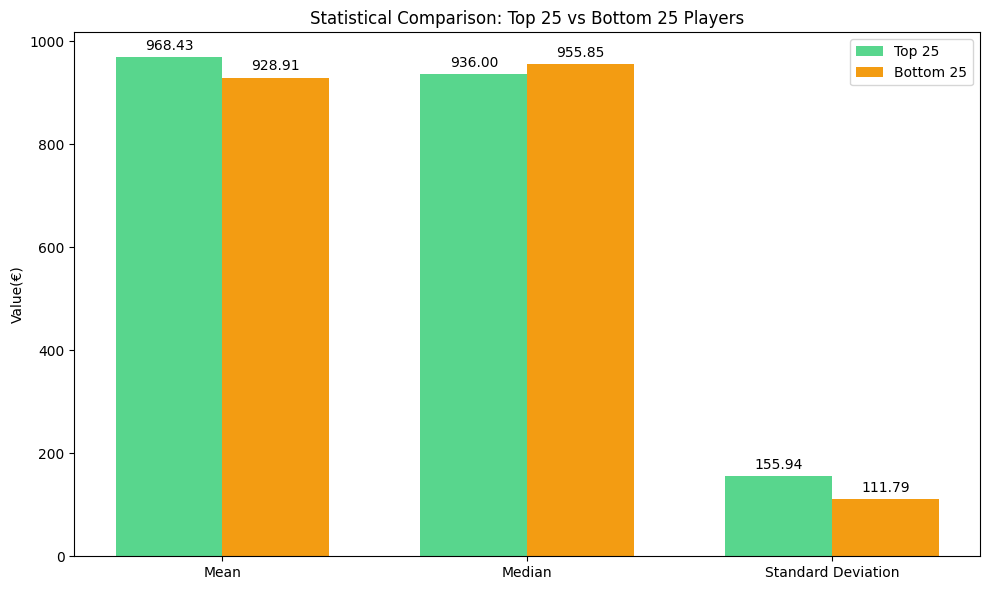

In [22]:
# BAR CHART
categories = ['Mean', 'Median', 'Standard Deviation']
top_25 = [968.43, 936.00, 155.94]
bottom_25 = [928.91, 955.85, 111.79]

x = np.arange(len(categories)) 
width = 0.35  

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width/2, top_25, width, label='Top 25', color='#58d68d')
rects2 = ax.bar(x + width/2, bottom_25, width, label='Bottom 25', color='#f39c12')

ax.set_ylabel('Value(€)')
ax.set_title('Statistical Comparison: Top 25 vs Bottom 25 Players')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.savefig('Statistical_Comparison_Top_25_vs_Bottom_25.png', dpi=300)
plt.show()

In [23]:
top_25 = df_analysis.nsmallest(25, 'rank')
bottom_25 = df_analysis.nlargest(25, 'rank')

diff_mean = top_25_stats['mean'] - bottom_25_stats['mean']
diff_median = top_25_stats['median'] - bottom_25_stats['median']
diff_perc = (diff_mean / bottom_25_stats['mean']) * 100

print("\n" + "="*37)
print("CONFRONT BETWEEN TOP 25 AND BOTTOM 25")
print("="*37)
print(f"Mean difference:   {diff_mean:+.2f} ({diff_perc:+.2f}%)")
print(f"Median difference: {diff_median:+.2f}")

# STATISTICAL TEST 
t_stat, p_value = sp_stats.ttest_ind(top_25['total_army_cost'], 
                                    bottom_25['total_army_cost'])

print(f"\nIndependent T-test:")
print(f"  t-statistic: {t_stat:.4f}")
print(f"  p-value: {p_value:.4f}")

if p_value < 0.05:
    print(f"\n STATISTICALLY SIGNIFICANT DIFFERENCE (p < 0.05)")
    if diff_mean > 0:
        print("  > Top players spend significantly MORE")
    else:
        print("  > Top players spend significantly LESS")
else:
    print(f"\n STATISTICALLY NON-SIGNIFICANT DIFFERENCE (p ≥ 0.05)")


CONFRONT BETWEEN TOP 25 AND BOTTOM 25
Mean difference:   +39.52 (+4.25%)
Median difference: -19.85

Independent T-test:
  t-statistic: 1.0299
  p-value: 0.3082

 STATISTICALLY NON-SIGNIFICANT DIFFERENCE (p ≥ 0.05)


## 2. Meta analysis

### 2.1 There is any kind of correlation between the army and their performance?

For example: The army that are used the most are the one who tend to win the most? or are the one less played?

In [24]:
# PREPARATION OF DATA 

# 1. Popularity: count how many players use each army
army_popularity = df_players.groupby('army').size().reset_index(name='player_count')

# 2. Performance: average win rate per army
army_performance = df_players.groupby('army').agg({
    'wins': 'mean',
    'losses': 'mean',
    'ties': 'mean',
    'rank': 'mean'
}).reset_index()

# 3. Win Rate: calculate win rate percentage for each player
total_matches_per_player = df_players['wins'] + df_players['losses'] + df_players['ties']
df_players['win_rate'] = (df_players['wins'] / total_matches_per_player * 100).fillna(0)

army_win_rate = df_players.groupby('army')['win_rate'].mean().reset_index()
army_win_rate.columns = ['army', 'avg_win_rate']

# 4. Combine all metrics in one DataFrame
army_analysis = army_popularity.merge(army_performance, on='army')
army_analysis = army_analysis.merge(army_win_rate, on='army')

# 5. Sort by popularity
army_analysis = army_analysis.sort_values('player_count', ascending=False)

print(f"\nTotal different armies in the tournament: {len(army_analysis)}")
print(f"\nTop 10 armies by popularity:")
print(army_analysis[['army', 'player_count', 'avg_win_rate', 'wins', 'rank']].head(10).to_string(index=False))



Total different armies in the tournament: 27

Top 10 armies by popularity:
                    army  player_count  avg_win_rate     wins       rank
space marines (astartes)            32     50.502232 4.031250 192.781250
                 aeldari            31     53.168203 4.225806 182.064516
      adeptus mechanicus            28     58.609694 4.678571 132.428571
            world eaters            23     50.000000 4.000000 216.826087
             death guard            23     42.080745 3.347826 245.304348
        imperial knights            20     39.375000 3.150000 262.950000
                 necrons            18     48.115079 3.833333 209.388889
     chaos space marines            16     47.656250 3.812500 207.375000
             t'au empire            16     48.660714 3.875000 189.562500
        adepta sororitas            16     58.593750 4.687500 144.500000


In [25]:
# CORRELATION ANALYSIS: Popularity vs Win Rate

print("\n" + "="*36)
print("CORRELATION: POPULARITY vs WIN RATE")
print("="*36)

corr_pearson, p_value_pearson = stats.pearsonr(
    army_analysis['player_count'], 
    army_analysis['avg_win_rate']
)

corr_spearman, p_value_spearman = stats.spearmanr(
    army_analysis['player_count'], 
    army_analysis['avg_win_rate']
)

print(f"\nPearson correlation: {corr_pearson:.4f} (p-value: {p_value_pearson:.4f})")
print(f"Spearman correlation: {corr_spearman:.4f} (p-value: {p_value_spearman:.4f})")

if p_value_spearman < 0.05:
    print(f"\n SIGNIFICANT CORRELATION (p < 0.05)")
    if corr_spearman > 0:
        print("The most popular armies tend to have higher win rates")
        print("(Meta effect: players choose strong factions)")
    else:
        print("The most popular armies tend to have lower win rates")
        print("(Underdog effect: niche factions perform better)")
else:
    print(f"\nCorrelation ISN'T significant (p ≥ 0.05)")
    print("Popularity is NOT correlated with performance")




CORRELATION: POPULARITY vs WIN RATE

Pearson correlation: 0.0007 (p-value: 0.9974)
Spearman correlation: -0.0538 (p-value: 0.7898)

Correlation ISN'T significant (p ≥ 0.05)
Popularity is NOT correlated with performance


In [26]:
# CORRELATION ANALYSIS: Popularity vs Mean Rank
print("\n" + "="*36)
print("CORRELATION: POPULARITY vs MEAN RANK")
print("="*36)

corr_rank_pearson, p_value_rank_pearson = stats.pearsonr(
    army_analysis['player_count'], 
    army_analysis['rank']
)

corr_rank_spearman, p_value_rank_spearman = stats.spearmanr(
    army_analysis['player_count'], 
    army_analysis['rank']
)

print(f"\nPearson correlation: {corr_rank_pearson:.4f} (p-value: {p_value_rank_pearson:.4f})")
print(f"Spearman correlation: {corr_rank_spearman:.4f} (p-value: {p_value_rank_spearman:.4f})")

if p_value_rank_spearman < 0.05:
    print(f"\n SIGNIFICANT CORRELATION (p < 0.05)")
    if corr_rank_spearman > 0:
        print("The most popular armies tend to have higher rank positions (worse performance)")
        print("(Meta effect: players choose strong factions)")
    else:
        print("The most popular armies tend to have lower rank positions (better performance)")
        print("(Underdog effect: niche factions perform better)")
else:
    print(f"\nCorrelation ISN'T significant (p ≥ 0.05)")
    print("Popularity is NOT correlated with performance")



CORRELATION: POPULARITY vs MEAN RANK

Pearson correlation: 0.0138 (p-value: 0.9454)
Spearman correlation: 0.1666 (p-value: 0.4062)

Correlation ISN'T significant (p ≥ 0.05)
Popularity is NOT correlated with performance


In [27]:
# MAINSTREAM vs NICHE

print("\n" + "="*20)
print("MAINSTREAM vs NICHE")
print("="*20)

threshold_mainstream = army_analysis['player_count'].quantile(0.67)
threshold_niche = army_analysis['player_count'].quantile(0.33)

army_analysis['category'] = pd.cut(
    army_analysis['player_count'],
    bins=[0, threshold_niche, threshold_mainstream, float('inf')],
    labels=['Niche', 'Mid', 'Mainstream']
)

category_stats = army_analysis.groupby('category').agg({
    'player_count': ['count', 'mean'],
    'avg_win_rate': ['mean', 'std'],
    'wins': 'mean'
}).round(2)

print("\nStatistiche per categoria:")
print(category_stats)


MAINSTREAM vs NICHE

Statistiche per categoria:
           player_count        avg_win_rate        wins
                  count   mean         mean   std  mean
category                                               
Niche                12   9.50        50.73  8.35  4.06
Mid                   8  14.12        47.70  5.36  3.81
Mainstream            7  25.00        48.84  6.51  3.90


/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/1546055616.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  category_stats = army_analysis.groupby('category').agg({


In [28]:
# MAINSTREAM & NICHE INFORMATIONS

mainstream = army_analysis[army_analysis['category'] == 'Mainstream']
niche = army_analysis[army_analysis['category'] == 'Niche']

print(f"\n--- MAINSTREAM ARMIES (top 33% popularity) ---")
print(f"Number of armies: {len(mainstream)}")
print(f"Average win rate: {mainstream['avg_win_rate'].mean():.2f}%")
print(f"Average rank: {mainstream['rank'].mean():.2f}")
print("\nMainstream armies:")
print(mainstream[['army', 'player_count', 'avg_win_rate']].to_string(index=False))

print(f"\n--- NICHE ARMIES (bottom 33% popularity) ---")
print(f"Number of armies: {len(niche)}")
print(f"Average win rate: {niche['avg_win_rate'].mean():.2f}%")
print(f"Average rank: {niche['rank'].mean():.2f}")
print("\nNiche armies:")
print(niche[['army', 'player_count', 'avg_win_rate']].to_string(index=False))


--- MAINSTREAM ARMIES (top 33% popularity) ---
Number of armies: 7
Average win rate: 48.84%
Average rank: 205.96

Mainstream armies:
                    army  player_count  avg_win_rate
space marines (astartes)            32     50.502232
                 aeldari            31     53.168203
      adeptus mechanicus            28     58.609694
            world eaters            23     50.000000
             death guard            23     42.080745
        imperial knights            20     39.375000
                 necrons            18     48.115079

--- NICHE ARMIES (bottom 33% popularity) ---
Number of armies: 12
Average win rate: 50.73%
Average rank: 193.03

Niche armies:
             army  player_count  avg_win_rate
leagues of votann            11     48.863636
         tyranids            11     55.681818
   black templars            11     46.590909
         drukhari            11     54.545455
genestealers cult            11     46.590909
 adeptus custodes            11     35

In [29]:
# STATISTICAL TEST

if len(mainstream) > 0 and len(niche) > 0:
    t_stat, p_value = stats.ttest_ind(mainstream['avg_win_rate'], niche['avg_win_rate'])
    print(f"\n--- T-TEST: Mainstream vs Niche ---")
    print(f"t-statistic: {t_stat:.4f}")
    print(f"p-value: {p_value:.4f}")
    
    if p_value < 0.05:
        diff = mainstream['avg_win_rate'].mean() - niche['avg_win_rate'].mean()
        print(f" The difference is SIGNIFICANT (p < 0.05)")
        if diff > 0:
            print(f"The mainstream armies performance BETTER (+{diff:.2f}% win rate)")
        else:
            print(f"Niche armies performance BETTER (+{abs(diff):.2f}% win rate)")
    else:
        print(f"\nThe difference ISN'T significant")


--- T-TEST: Mainstream vs Niche ---
t-statistic: -0.5131
p-value: 0.6145

The difference ISN'T significant


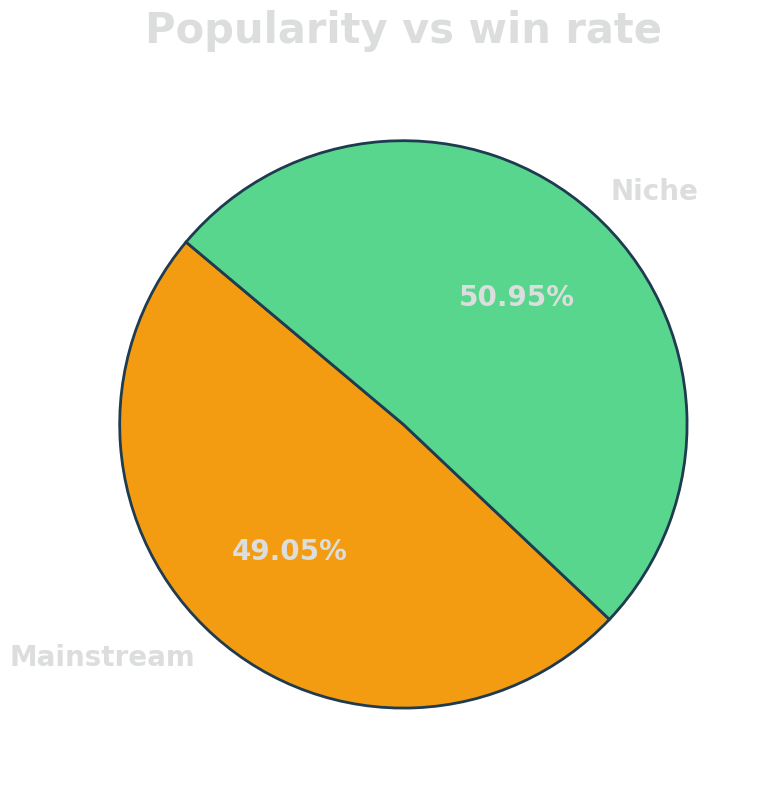

In [30]:
# CAKE CHART

labels = ['Mainstream', 'Niche']
sizes = [48.84, 50.73]
colors = ['#f39c12', '#58d68d'] 
TEXT_COLOR = '#dcdddd' 

fig, ax = plt.subplots(figsize=(8, 8))
fig.patch.set_alpha(0) 
ax.set_facecolor("none") 

patches, texts, autotexts = ax.pie(
    sizes, 
    labels=labels, 
    autopct='%1.2f%%', 
    startangle=140, 
    colors=colors,
    textprops={'color': TEXT_COLOR, 'fontsize': 20, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': '#1e3b50', 'linewidth': 2}
)

plt.title('Popularity vs win rate', color=TEXT_COLOR, fontsize=30, pad=20, fontweight='bold')
plt.tight_layout()

plt.savefig('grafico_torta_niche.png', transparent=True, dpi=300)
plt.show()

### 2.2 For the most popula armies there is a specific detachment which performe better?

For example: If an army has two or more detachment, there is one that is used to performe better?

1. The first step is the one to understand which army we've got

In [31]:
# POPULARITY OF THE ARMY

print("="*34)
print("POPULARITY OF THE ARMY - GROUP BY")
print("="*34)

army_counts = df_players.groupby('army').size().reset_index(name='player_count')
army_counts = army_counts.sort_values('player_count', ascending=False).reset_index(drop=True)
total_players = len(df_players)
army_counts['percentage'] = (army_counts['player_count'] / total_players * 100).round(2)

print(f"\nTotal players: {total_players}")
print(f"Total different armies: {len(army_counts)}\n")

for idx, row in army_counts.iterrows():
    print(f"{idx+1:2d}. {row['army']:30s} - {row['player_count']:3d} player ({row['percentage']:5.2f}%)")

print("\n" + "="*18)
print("SUMMARY STATISTICS")
print("="*18)
print(f"Most popular army: {army_counts.iloc[0]['army']} ({army_counts.iloc[0]['player_count']} players)")
print(f"Least popular army: {army_counts.iloc[-1]['army']} ({army_counts.iloc[-1]['player_count']} players)")
print(f"\nAverage players per army: {army_counts['player_count'].mean():.2f}")
print(f"Median players per army: {army_counts['player_count'].median():.0f}")
print(f"Standard deviation: {army_counts['player_count'].std():.2f}")

POPULARITY OF THE ARMY - GROUP BY

Total players: 402
Total different armies: 27

 1. space marines (astartes)       -  32 player ( 7.96%)
 2. aeldari                        -  31 player ( 7.71%)
 3. adeptus mechanicus             -  28 player ( 6.97%)
 4. world eaters                   -  23 player ( 5.72%)
 5. death guard                    -  23 player ( 5.72%)
 6. imperial knights               -  20 player ( 4.98%)
 7. necrons                        -  18 player ( 4.48%)
 8. chaos space marines            -  16 player ( 3.98%)
 9. t'au empire                    -  16 player ( 3.98%)
10. adepta sororitas               -  16 player ( 3.98%)
11. orks                           -  14 player ( 3.48%)
12. chaos knights                  -  13 player ( 3.23%)
13. blood angels                   -  13 player ( 3.23%)
14. chaos daemons                  -  13 player ( 3.23%)
15. astra militarum                -  12 player ( 2.99%)
16. leagues of votann              -  11 player ( 2.74%)
17. ty

2. We can start now the detachment analysis, and the first step is to identify the armies which have at least 15 players

In [32]:
# DETACHMENTS (> mean and median)

print("="*38)
print("ANALYSIS OF FACTIONS AND DETACHMENTS")
print("="*38)

popular_armies = army_counts[army_counts['player_count'] >= 15]['army'].tolist()

print(f"\nArmies with at least 15 players: {len(popular_armies)}")
print("\nAnalyzed factions:")
for army in sorted(popular_armies):
    count = army_counts[army_counts['army'] == army]['player_count'].values[0]
    print(f"  - {army:30s} ({count} players)")


ANALYSIS OF FACTIONS AND DETACHMENTS

Armies with at least 15 players: 10

Analyzed factions:
  - adepta sororitas               (16 players)
  - adeptus mechanicus             (28 players)
  - aeldari                        (31 players)
  - chaos space marines            (16 players)
  - death guard                    (23 players)
  - imperial knights               (20 players)
  - necrons                        (18 players)
  - space marines (astartes)       (32 players)
  - t'au empire                    (16 players)
  - world eaters                   (23 players)


3. First of all we would like to know the performance of the army we've selected

In [33]:
# PERFORMANCE OF THE MOST POPULAR ARMIES

print("\n" + "="*38)
print("PERFORMANCE OF THE MOST POPULAR ARMIES")
print("="*38)

df_popular = df_players[df_players['army'].isin(popular_armies)].copy()

total_matches = df_popular['wins'] + df_popular['losses'] + df_popular['ties']
df_popular['win_rate'] = (df_popular['wins'] / total_matches * 100).fillna(0)

faction_stats = df_popular.groupby('army').agg({
    'win_rate': ['mean', 'std', 'count'],
    'wins': 'mean',
    'id_player': 'count'
}).round(2)

faction_stats.columns = ['avg_win_rate', 'std_win_rate', 'sample_size', 
                         'avg_wins', 'player_count']
faction_stats = faction_stats.reset_index()
faction_stats = faction_stats.sort_values('player_count', ascending=False)

print("\nClassification for army and their win rate:")
print(faction_stats[['army', 'player_count', 'avg_wins', 'avg_win_rate', 'std_win_rate']].to_string(index=False))



PERFORMANCE OF THE MOST POPULAR ARMIES

Classification for army and their win rate:
                    army  player_count  avg_wins  avg_win_rate  std_win_rate
space marines (astartes)            32      4.03         50.50         14.18
                 aeldari            31      4.23         53.17         18.58
      adeptus mechanicus            28      4.68         58.61         15.34
             death guard            23      3.35         42.08         18.29
            world eaters            23      4.00         50.00         13.06
        imperial knights            20      3.15         39.38         19.14
                 necrons            18      3.83         48.12         18.57
        adepta sororitas            16      4.69         58.59         11.83
     chaos space marines            16      3.81         47.66         18.38
             t'au empire            16      3.88         48.66         16.69


4. Now, we'll try to understand for each army, if the detachment with the highest win rate is really better or it has been just lucky

In [34]:
# DETACHMENT ANALYSIS FOR EACH FACTION

print("\n" + "="*36)
print("DETACHMENT ANALYSIS FOR EACH FACTION")
print("="*36)

MIN_PLAYERS_DETACHMENT = 5  
CONFIDENCE_LEVEL = 0.05     

print(f"\nStatistical parameters:")
print(f"1. Min sample size for detachment: {MIN_PLAYERS_DETACHMENT} players")
print(f"2. Confidence level: {(1-CONFIDENCE_LEVEL)*100}% (p-value < {CONFIDENCE_LEVEL})")

# Create dictionary to save results
detachment_analysis = {}
detachment_statistical_tests = {}

for army in popular_armies:
    print(f"\n{'='*60}")
    print(f"FACTION: {army.upper()}")
    print(f"{'='*60}")
    
    army_players = df_popular[df_popular['army'] == army].copy()
    
    detachment_stats = army_players.groupby('detachment').agg({
        'win_rate': ['mean', 'std', 'count'],
        'wins': 'mean',
        'id_player': 'count'
    }).round(2)

    detachment_stats.columns = ['avg_win_rate', 'std_win_rate', 'n_players', 'avg_wins', 'player_count']
    detachment_stats = detachment_stats.reset_index()
    
    detachment_stats_filtered = detachment_stats[detachment_stats['n_players'] >= MIN_PLAYERS_DETACHMENT].copy()
    detachment_stats_all = detachment_stats.copy()
    
    detachment_stats_filtered['ci_95'] = 1.96 * (detachment_stats_filtered['std_win_rate'] / 
                                                   np.sqrt(detachment_stats_filtered['n_players']))
    
    detachment_stats_filtered = detachment_stats_filtered.sort_values('avg_win_rate', ascending=False)
    
    detachment_analysis[army] = detachment_stats_filtered

    print(f"\nTotal detachments used: {len(detachment_stats_all)}")
    print(f"Detachments with adequate sample size (>={MIN_PLAYERS_DETACHMENT}): {len(detachment_stats_filtered)}")

    if len(detachment_stats_filtered) == 0:
        print(f"WARNING: No detachment has adequate sample size for reliable analysis!")
        print(f"\nAvailable detachments (statistically unreliable):")
        print(detachment_stats_all.sort_values('avg_win_rate', ascending=False).to_string(index=False))
        continue
    
    excluded = detachment_stats_all[detachment_stats_all['n_players'] < MIN_PLAYERS_DETACHMENT]
    if len(excluded) > 0:
        print(f"\nEXCLUDED detachments (sample size < {MIN_PLAYERS_DETACHMENT}):")
        for _, row in excluded.iterrows():
            print(f"   - {row['detachment']:30s} (n={int(row['n_players'])}, WR={row['avg_win_rate']:.1f}%) NOT RELIABLE")

    print(f"\nVALID detachments (sample size >={MIN_PLAYERS_DETACHMENT}):")
    print(detachment_stats_filtered[['detachment', 'n_players', 'avg_win_rate', 'std_win_rate', 'ci_95']].to_string(index=False))
    
    # === STATISTICAL TEST: Comparison between detachments ===
    if len(detachment_stats_filtered) >= 2:
        print(f"\nSTATISTICAL TEST: Comparison between detachments")
        
        # Take best detachment and compare with others
        best_det = detachment_stats_filtered.iloc[0]
        best_det_players = army_players[army_players['detachment'] == best_det['detachment']]
        
        print(f"\n   Reference detachment (best): {best_det['detachment']}")
        print(f"   Win Rate: {best_det['avg_win_rate']:.2f}% +/- {best_det['ci_95']:.2f}% (95% CI)")
        
        test_results = []
        
        for idx, row in detachment_stats_filtered.iloc[1:].iterrows():
            other_det_players = army_players[army_players['detachment'] == row['detachment']]
            
            # Independent T-test
            t_stat, p_value = stats.ttest_ind(
                best_det_players['win_rate'],
                other_det_players['win_rate']
            )
            
            # Effect size (Cohen's d)
            pooled_std = np.sqrt((best_det_players['win_rate'].std()**2 + 
                                  other_det_players['win_rate'].std()**2) / 2)
            cohens_d = (best_det_players['win_rate'].mean() - 
                       other_det_players['win_rate'].mean()) / pooled_std if pooled_std > 0 else 0
            
            diff = best_det['avg_win_rate'] - row['avg_win_rate']
            
            test_results.append({
                'detachment': row['detachment'],
                'win_rate': row['avg_win_rate'],
                'diff': diff,
                'p_value': p_value,
                'cohens_d': cohens_d,
                'significant': p_value < CONFIDENCE_LEVEL
            })
            
            significance = "SIGNIFICANT" if p_value < CONFIDENCE_LEVEL else "Not significant"
            effect = "Large" if abs(cohens_d) > 0.8 else "Medium" if abs(cohens_d) > 0.4 else "Small"
            
            print(f"\n   vs {row['detachment']}:")
            print(f"      Difference: {diff:+.2f}% win rate")
            print(f"      p-value: {p_value:.4f} -> {significance}")
            print(f"      Effect size (Cohen's d): {cohens_d:.3f} ({effect})")
        
        # Save test results
        detachment_statistical_tests[army] = test_results
        
        # CONCLUSION
        print(f"\n   {'='*60}")
        significant_diffs = sum([1 for r in test_results if r['significant']])
        if significant_diffs > 0:
            print(f"   RESULT: {best_det['detachment']} is SIGNIFICANTLY BETTER")
            print(f"           compared to {significant_diffs}/{len(test_results)} other detachment(s)")
        else:
            print(f"   RESULT: No statistically significant difference")
            print(f"           Detachments are balanced (or insufficient sample size)")
    
    elif len(detachment_stats_filtered) == 1:
        print(f"\nWARNING: Only 1 detachment has sufficient sample size: {detachment_stats_filtered.iloc[0]['detachment']}")
        print(f"         Cannot perform statistical comparisons")
    
    # Identify best detachment (among valid ones)
    if len(detachment_stats_filtered) > 0:
        best_detachment = detachment_stats_filtered.iloc[0]
        print(f"\n{'='*60}")
        print(f"STRONGEST DETACHMENT (statistically reliable):")
        print(f"   {best_detachment['detachment']}")
        print(f"   Win Rate: {best_detachment['avg_win_rate']:.2f}% +/- {best_detachment['ci_95']:.2f}%")
        print(f"   Used by: {int(best_detachment['n_players'])} players ({best_detachment['n_players']/len(army_players)*100:.1f}% of faction)")


DETACHMENT ANALYSIS FOR EACH FACTION

Statistical parameters:
1. Min sample size for detachment: 5 players
2. Confidence level: 95.0% (p-value < 0.05)

FACTION: SPACE MARINES (ASTARTES)

Total detachments used: 7
Detachments with adequate sample size (>=5): 2

EXCLUDED detachments (sample size < 5):
   - anvil siege force              (n=1, WR=37.5%) NOT RELIABLE
   - firestorm assault force        (n=1, WR=62.5%) NOT RELIABLE
   - ironstorm spearhead            (n=2, WR=50.0%) NOT RELIABLE
   - stormlance task force          (n=2, WR=56.2%) NOT RELIABLE
   - vanguard spearhead             (n=2, WR=56.2%) NOT RELIABLE

VALID detachments (sample size >=5):
        detachment  n_players  avg_win_rate  std_win_rate    ci_95
gladius task force         10         51.25         16.08 9.966487
  shadowmark talon         14         48.47         15.78 8.266069

STATISTICAL TEST: Comparison between detachments

   Reference detachment (best): gladius task force
   Win Rate: 51.25% +/- 9.97% (9

5. Let's proceed doing box plot, to have a graphical output

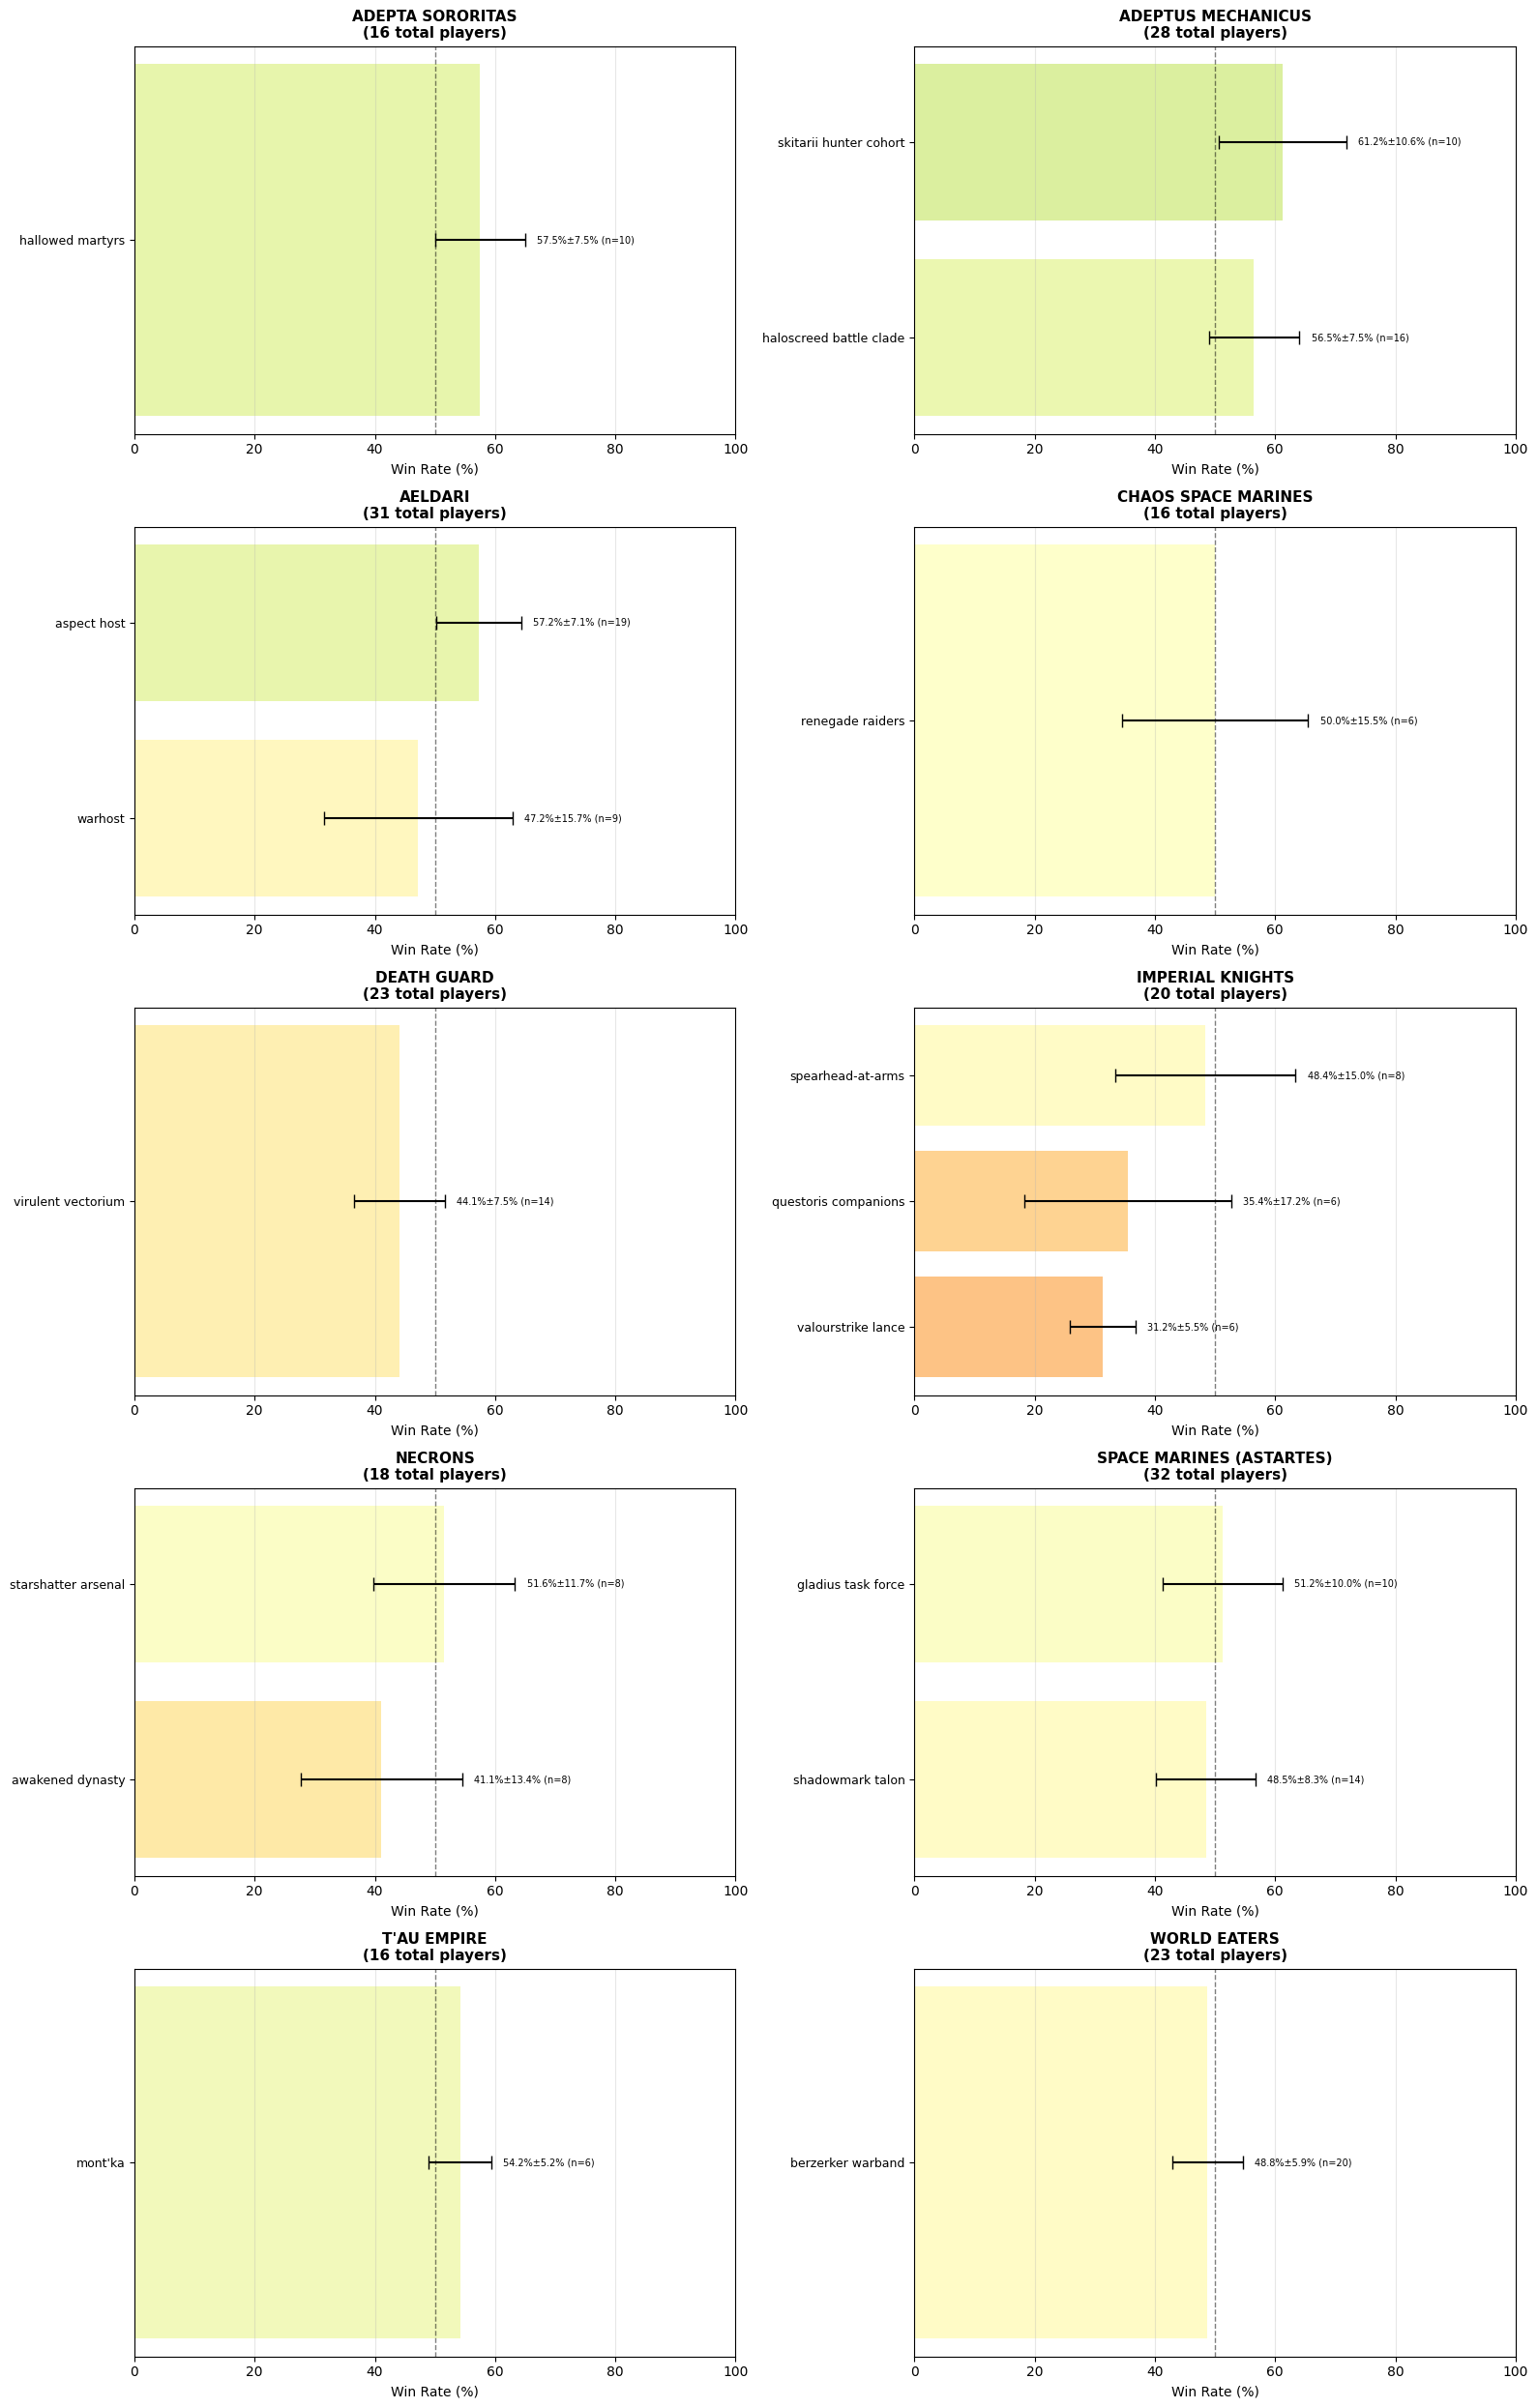

In [35]:
# BOX PLOT FOR EACH ARMY

n_factions = len(popular_armies)
n_cols = 2
n_rows = int(np.ceil(n_factions / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5*n_rows))
axes = axes.flatten() if n_factions > 1 else [axes]

for idx, army in enumerate(sorted(popular_armies)):
    det_df = detachment_analysis.get(army, pd.DataFrame())
    
    if len(det_df) == 0:
        axes[idx].text(0.5, 0.5, f'{army}\nNo detachment with\nadequate sample size', 
                      ha='center', va='center', fontsize=12, style='italic')
        axes[idx].set_xlim(0, 1)
        axes[idx].set_ylim(0, 1)
        axes[idx].axis('off')
        continue
    
    det_df = det_df.sort_values('avg_win_rate', ascending=True)
    
    colors = plt.cm.RdYlGn(det_df['avg_win_rate'] / 100)
    
    bars = axes[idx].barh(range(len(det_df)), det_df['avg_win_rate'], 
                          xerr=det_df['ci_95'], capsize=5, color=colors, alpha=0.8)
    
    axes[idx].axvline(x=50, color='black', linestyle='--', alpha=0.5, linewidth=1)
    
    axes[idx].set_yticks(range(len(det_df)))
    axes[idx].set_yticklabels(det_df['detachment'], fontsize=9)
    axes[idx].set_xlabel('Win Rate (%)', fontsize=10)
    axes[idx].set_title(f'{army.upper()}\n({len(df_popular[df_popular["army"]==army])} total players)', 
                        fontsize=11, fontweight='bold')
    axes[idx].grid(axis='x', alpha=0.3)
    axes[idx].set_xlim(0, 100)
    
    for i, (_, row) in enumerate(det_df.iterrows()):
        label = f"{row['avg_win_rate']:.1f}%±{row['ci_95']:.1f}% (n={int(row['n_players'])})"
        axes[idx].text(row['avg_win_rate'] + row['ci_95'] + 2, i, label, 
                      va='center', fontsize=7)

for idx in range(n_factions, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()


Salvato: adeptus_mechanicus_winrate.png


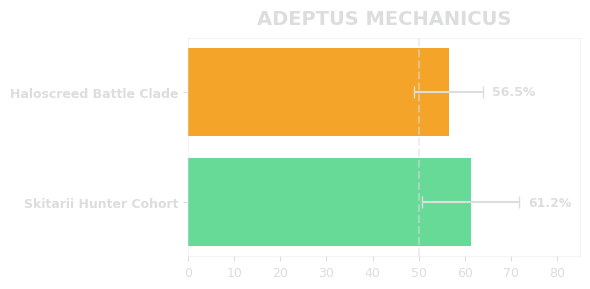

Salvato: imperial_knights_winrate.png


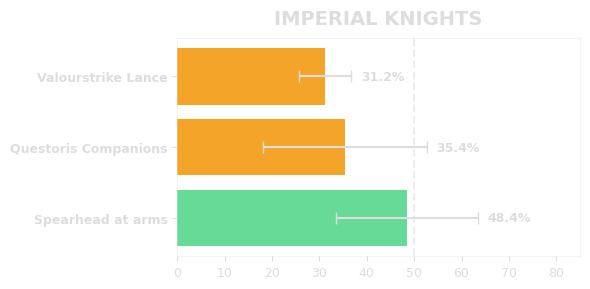

Salvato: aeldari_winrate.png


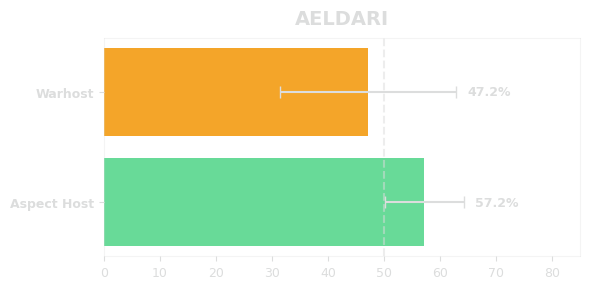

In [36]:
# BOX PLOT FOR POWERPOINT

factions_data = {
    'Adeptus Mechanicus': {
        'labels': ['Skitarii Hunter Cohort', 'Haloscreed Battle Clade'],
        'rates': [61.25, 56.47],
        'ci': [10.62, 7.53]
    },
    'Imperial Knights': {
        'labels': ['Spearhead at arms', 'Questoris Companions', 'Valourstrike Lance'],
        'rates': [48.44, 35.42, 31.25],
        'ci': [14.96, 17.23, 5.48]
    },
    'Aeldari': {
        'labels': ['Aspect Host', 'Warhost'],
        'rates': [57.24, 47.22],
        'ci': [7.09, 15.70]
    }
}

TEXT_COLOR = '#dcdddd'
VERDE_BEST = '#58d68d'
ARANCIO_REST = '#f39c12'

for army, data in factions_data.items():
    fig, ax = plt.subplots(figsize=(6, 3)) 
    fig.patch.set_alpha(0) 
    ax.set_facecolor("none")
    
    rates = np.array(data['rates'])
    labels = data['labels']
    ci = data['ci']
    
    idx_best = np.argmax(rates)
    bar_colors = [VERDE_BEST if j == idx_best else ARANCIO_REST for j in range(len(rates))]
    
    y_pos = np.arange(len(labels))
    
    ax.barh(y_pos, rates, xerr=ci, capsize=4, 
            color=bar_colors, alpha=0.9, ecolor=TEXT_COLOR)

    ax.axvline(x=50, color=TEXT_COLOR, linestyle='--', alpha=0.5, linewidth=1.5)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=10, color=TEXT_COLOR, fontweight='bold')
    ax.set_title(army.upper(), fontsize=14, fontweight='bold', color=TEXT_COLOR, pad=10)
    ax.set_xlim(0, 85)
    
    ax.tick_params(colors=TEXT_COLOR, labelsize=9)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.3)

    for j, r in enumerate(rates):
        ax.text(r + ci[j] + 2, j, f"{r:.1f}%", 
                va='center', fontsize=9, color=TEXT_COLOR, fontweight='bold')

    plt.tight_layout()

    file_name = f"{army.replace(' ', '_').lower()}_winrate.png"
    plt.savefig(file_name, transparent=True, dpi=300)
    print(f"Salvato: {file_name}")
    plt.show()

6. Best army and best combination

In [37]:
# BEST ARMY AND BEST COMBINATIONS

all_combinations = []
for army, det_df in detachment_analysis.items():
    for _, row in det_df.iterrows():
        all_combinations.append({
            'army': army,
            'detachment': row['detachment'],
            'win_rate': row['avg_win_rate'],
            'ci_95': row['ci_95'],
            'n_players': row['n_players'],
        })

combo_df = pd.DataFrame(all_combinations)
combo_df = combo_df.sort_values('win_rate', ascending=False)

print("="*24)
print("CONCLUSIONS AND INSIGHTS")
print("="*24)

best_faction = faction_stats.iloc[0]
print(f"\nSTRONGEST ARMY OVERALL: {best_faction['army']}")
print(f"   Average Win Rate: {best_faction['avg_win_rate']:.2f}%")
print(f"   Players: {int(best_faction['player_count'])}")

if best_faction['army'] in detachment_analysis and len(detachment_analysis[best_faction['army']]) > 0:
    best_det_for_best = detachment_analysis[best_faction['army']].iloc[0]
    print(f"   Best Detachment: {best_det_for_best['detachment']}")
    print(f"   Detachment Win Rate: {best_det_for_best['avg_win_rate']:.2f}% ± {best_det_for_best['ci_95']:.2f}%")

if len(combo_df) > 0:
    print(f"\nSTRONGEST COMBINATION (STATISTICALLY RELIABLE):")
    best_combo = combo_df.iloc[0]
    print(f"   {best_combo['army']} - {best_combo['detachment']}")
    print(f"   Win Rate: {best_combo['win_rate']:.2f}% ± {best_combo['ci_95']:.2f}%")
    print(f"   Sample size: {int(best_combo['n_players'])} players")

CONCLUSIONS AND INSIGHTS

STRONGEST ARMY OVERALL: space marines (astartes)
   Average Win Rate: 50.50%
   Players: 32
   Best Detachment: gladius task force
   Detachment Win Rate: 51.25% ± 9.97%

STRONGEST COMBINATION (STATISTICALLY RELIABLE):
   adeptus mechanicus - skitarii hunter cohort
   Win Rate: 61.25% ± 10.62%
   Sample size: 10 players


## 3. Unity analysis

### 3.1 Are there any units that appear to be essential?

1. First of all we would like to analyze the core units in the top 5 most played armies.

In [38]:
# STUDY OF THE MOST PLAYED ARMIES

print("="*57)
print("INDISPENSABLE UNITS ANALYSIS: TOP 5 MOST PLAYED ARMIES")
print("="*57)

CORE_THRESHOLD = 50  # Min % of usage to be considered important
MIN_SAMPLE_WITHOUT = 3  # Min number of players without unit for the t-test

top_5_armies = df_players.groupby('army').size().sort_values(ascending=False).head(5).index.tolist()

print(f"\nTop 5 most played armies:")
for i, army in enumerate(top_5_armies, 1):
    count = len(df_players[df_players['army'] == army])
    print(f"  {i}. {army}: {count} players")

df_wr = df_players[['id_player', 'army', 'wins', 'losses', 'ties']].copy()
df_wr['total_games'] = df_wr['wins'] + df_wr['losses'] + df_wr['ties']
df_wr['win_rate'] = (df_wr['wins'] / df_wr['total_games'] * 100).fillna(0)

all_units_results = []  
faction_summary = []    


INDISPENSABLE UNITS ANALYSIS: TOP 5 MOST PLAYED ARMIES

Top 5 most played armies:
  1. space marines (astartes): 32 players
  2. aeldari: 31 players
  3. adeptus mechanicus: 28 players
  4. world eaters: 23 players
  5. death guard: 23 players


In [39]:
# IDENTIFICATION OF CORE UNITS

print(f"\n{'='*47}")
print("CORE UNITS IDENTIFICATION AND WIN RATE ANALYSIS")
print(f"{'='*47}")

for army in top_5_armies:
    print(f"\n{'='*47}")
    print(f"ARMY: {army.upper()}")
    print(f"{'='*47}")
    
    army_player_ids = df_players[df_players['army'] == army]['id_player'].unique()
    n_army_players = len(army_player_ids)
    
    print(f"\nTotal players: {n_army_players}")
    print(f"Core threshold: {CORE_THRESHOLD}% (min {int(n_army_players * CORE_THRESHOLD / 100)} players)")

    # We need every unit used by these players and check which of them is above the core threshold
    army_units = df_army_list_units[df_army_list_units['id_player'].isin(army_player_ids)]
    
    unit_stats = army_units.groupby('clean_name').agg({
        'id_player': 'nunique',
        'quantity': 'mean',
        'points': 'mean'
    }).reset_index()
    
    unit_stats.columns = ['unit', 'player_count', 'avg_quantity', 'avg_points']
    unit_stats['popularity_pct'] = (unit_stats['player_count'] / n_army_players) * 100
    
    core_units = unit_stats[unit_stats['popularity_pct'] >= CORE_THRESHOLD].sort_values(
        'popularity_pct', ascending=False
    )
    
    print(f"\nCore units found (usage >= {CORE_THRESHOLD}%): {len(core_units)}")
    
    if len(core_units) == 0:
        print(f"WARNING: No units exceed {CORE_THRESHOLD}% usage threshold")
        print("Consider lowering the threshold for this faction.")
        faction_summary.append({
            'Army': army,
            'Core Units Found': 0,
            'P-Value (Faction)': np.nan,
            'Significant': 'N/A',
            'Meta Advantage (%)': np.nan
        })
        continue

    # In this part we will print the information about unit statistics
    print(f"\n{'Unit':<35} {'Pop %':<8} {'Avg Qty':<9} {'WR With':<10} {'WR Without':<12} {'WR Diff':<10} {'Sig':<5}")
    print("-" * 100)
    
    unit_test_results = []  
    
    for _, row in core_units.iterrows():
        unit_name = row['unit']
        
        players_with = army_units[army_units['clean_name'] == unit_name]['id_player'].unique()
        players_without = np.setdiff1d(army_player_ids, players_with)
        
        wr_with = df_wr[df_wr['id_player'].isin(players_with)]['win_rate']
        wr_without = df_wr[df_wr['id_player'].isin(players_without)]['win_rate']
        
        wr_with_mean = wr_with.mean()
        wr_without_mean = wr_without.mean() if len(players_without) > 0 else np.nan
        wr_diff = wr_with_mean - wr_without_mean if not np.isnan(wr_without_mean) else 0
        
        if len(players_without) >= MIN_SAMPLE_WITHOUT:
            t_stat, p_value = stats.ttest_ind(wr_with, wr_without, equal_var=False)
            significant = p_value < 0.05
        else:
            p_value = np.nan
            significant = False
        
        sig_marker = "SIG" if significant else "-"
        
        print(f"{unit_name:<35} {row['popularity_pct']:>6.1f}% {row['avg_quantity']:>8.1f} {wr_with_mean:>9.2f}% {wr_without_mean:>11.2f}% {wr_diff:>+9.2f}% {sig_marker:<5}")
        
        all_units_results.append({
            'Army': army,
            'Unit': unit_name,
            'Popularity (%)': row['popularity_pct'],
            'Avg Quantity': row['avg_quantity'],
            'Avg Points': row['avg_points'],
            'Players With': len(players_with),
            'Players Without': len(players_without),
            'WR With Unit (%)': wr_with_mean,
            'WR Without Unit (%)': wr_without_mean,
            'WR Diff (%)': wr_diff,
            'P-Value': p_value,
            'Significant': significant
        })
        
        unit_test_results.append({
            'unit': unit_name,
            'p_value': p_value,
            'significant': significant,
            'wr_diff': wr_diff
        })
    
    print(f"\n{'-'*47}")
    print("FACTION-LEVEL STATISTICAL TEST:")
    print(f"{'-'*47}")
    print("Question: Do players using MORE core units have higher win rate?")

    # Calculate META-SCORE for each player (how many core units they use in their army)
    army_players_wr = df_wr[df_wr['id_player'].isin(army_player_ids)].copy()
    core_unit_names = core_units['unit'].tolist()
    
    player_core_counts = army_units[army_units['clean_name'].isin(core_unit_names)].groupby(
        'id_player'
    )['clean_name'].nunique()
    
    army_players_wr['meta_score'] = army_players_wr['id_player'].map(player_core_counts).fillna(0)
    
    median_score = army_players_wr['meta_score'].median()
    high_meta = army_players_wr[army_players_wr['meta_score'] > median_score]['win_rate']
    low_meta = army_players_wr[army_players_wr['meta_score'] <= median_score]['win_rate']
    
    print(f"\nCore units identified: {len(core_units)}")
    print(f"Median core units used per player: {median_score:.1f}")
    print(f"High meta group (>{median_score:.1f} core units): {len(high_meta)} players")
    print(f"Low meta group (<={median_score:.1f} core units): {len(low_meta)} players")
    
    # T-test between groups
    if len(high_meta) > 0 and len(low_meta) > 1:
        t_stat_meta, p_val_meta = stats.ttest_ind(high_meta, low_meta, equal_var=False)
        meta_diff = high_meta.mean() - low_meta.mean()
        meta_significant = p_val_meta < 0.05
        
        print(f"\nHigh meta WR: {high_meta.mean():.2f}%")
        print(f"Low meta WR: {low_meta.mean():.2f}%")
        print(f"Difference: {meta_diff:+.2f}%")
        print(f"P-value: {p_val_meta:.4f} {'[SIGNIFICANT]' if meta_significant else '[Not significant]'}")
        
        if meta_significant:
            print(f"\nCONCLUSION: For {army}, using core units IS statistically significant.")
            print(f"            Players using more core units win {meta_diff:+.2f}% more often.")
        else:
            print(f"\nCONCLUSION: For {army}, using core units is NOT statistically significant.")
            print(f"            The difference could be due to chance.")
        
        faction_summary.append({
            'Army': army,
            'Core Units Found': len(core_units),
            'P-Value (Faction)': p_val_meta,
            'Significant': 'YES' if meta_significant else 'NO',
            'Meta Advantage (%)': meta_diff
        })
    else:
        print("\nWARNING: Insufficient data for faction-level statistical test")
        faction_summary.append({
            'Army': army,
            'Core Units Found': len(core_units),
            'P-Value (Faction)': np.nan,
            'Significant': 'N/A',
            'Meta Advantage (%)': np.nan
        })


CORE UNITS IDENTIFICATION AND WIN RATE ANALYSIS

ARMY: SPACE MARINES (ASTARTES)

Total players: 32
Core threshold: 50% (min 16 players)

Core units found (usage >= 50%): 6

Unit                                Pop %    Avg Qty   WR With    WR Without   WR Diff    Sig  
----------------------------------------------------------------------------------------------------
intercessor squad                     87.5%      1.1     51.91%       40.62%    +11.29% -    
lieutenant with combi-weapon          78.1%      1.0     49.64%       53.57%     -3.93% -    
assault intercessors with jump packs   68.8%      1.9     48.46%       55.00%     -6.54% -    
inceptor squad                        59.4%      1.4     48.21%       53.85%     -5.63% -    
centurion devastator squad            56.2%      1.1     50.89%       50.00%     +0.89% -    
vanguard veteran squad with jump packs   53.1%      1.8     49.47%       51.67%     -2.19% -    

-----------------------------------------------
FACTION-LEVE

/Users/carlo_air_2021/Library/Python/3.9/lib/python/site-packages/scipy/stats/_axis_nan_policy.py:531: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


In [40]:
# T-TESTS FOR UNIT SIGNIFICANCE

print(f"\n{'='*30}")
print("STATISTICAL SIGNIFICANCE TESTS")
print(f"{'='*30}")

print(f"\n{'-'*80}")
print("LOCAL TESTS: Does unit choice matter for each faction?")
print(f"{'-'*80}")

df_faction_summary = pd.DataFrame(faction_summary)
df_faction_summary = df_faction_summary.drop_duplicates(subset=['Army']).reset_index(drop=True)

print("\n")
print(df_faction_summary.to_string(index=False))

print("\nINTERPRETATION:")
print("- P-Value < 0.05 = Unit choice IS statistically significant for this faction")
print("- Meta Advantage = WR difference between players using many vs few core units")

n_significant = sum(df_faction_summary['Significant'] == 'YES')
n_total = len(df_faction_summary[df_faction_summary['Significant'] != 'N/A'])

print(f"\nSUMMARY: {n_significant}/{n_total} factions show statistically significant impact of core units")


STATISTICAL SIGNIFICANCE TESTS

--------------------------------------------------------------------------------
LOCAL TESTS: Does unit choice matter for each faction?
--------------------------------------------------------------------------------


                    Army  Core Units Found  P-Value (Faction) Significant  Meta Advantage (%)
space marines (astartes)                 6           0.482209          NO           -3.634454
                 aeldari                12           0.319196          NO           -7.112332
      adeptus mechanicus                 8           0.768162          NO           -1.712454
            world eaters                10           0.708843          NO           -2.178030
             death guard                 9           0.633163          NO            3.586310

INTERPRETATION:
- P-Value < 0.05 = Unit choice IS statistically significant for this faction
- Meta Advantage = WR difference between players using many vs few core units

SUMMARY: 0/

In [41]:
# AT GLOBAL LEVEL

print(f"\n{'-'*80}")
print("GLOBAL TEST: Does unit choice matter across all factions?")
print(f"{'-'*80}")

df_all_units = pd.DataFrame(all_units_results)

global_meta_scores = []

for army in top_5_armies:
    army_player_ids = df_players[df_players['army'] == army]['id_player'].unique()
    army_units = df_army_list_units[df_army_list_units['id_player'].isin(army_player_ids)]
    
    core_units_this_army = df_all_units[
        (df_all_units['Army'] == army) & 
        (df_all_units['Popularity (%)'] >= CORE_THRESHOLD)
    ]['Unit'].tolist()
    
    for player_id in army_player_ids:
        player_units = army_units[army_units['id_player'] == player_id]['clean_name'].unique()
        n_core_used = len(set(player_units) & set(core_units_this_army))
        n_core_available = len(core_units_this_army)
        
        core_pct = (n_core_used / n_core_available * 100) if n_core_available > 0 else 0
        
        player_wr = df_wr[df_wr['id_player'] == player_id]['win_rate'].values
        win_rate = player_wr[0] if len(player_wr) > 0 else np.nan
        
        global_meta_scores.append({
            'id_player': player_id,
            'army': army,
            'n_core_used': n_core_used,
            'n_core_available': n_core_available,
            'core_usage_pct': core_pct,
            'win_rate': win_rate
        })

df_global_meta = pd.DataFrame(global_meta_scores).dropna(subset=['win_rate'])

print(f"\nDebug info:")
print(f"  Players in global dataset: {len(df_global_meta)}")
print(f"  Unique armies: {df_global_meta['army'].nunique()}")
print(f"  Breakdown by army:")
for army in top_5_armies:
    count = len(df_global_meta[df_global_meta['army'] == army])
    print(f"    - {army}: {count} players")

# Global correlation
r_global, p_global = stats.pearsonr(df_global_meta['core_usage_pct'], df_global_meta['win_rate'])

print(f"\nGlobal correlation test:")
print(f"  Variable 1: Percentage of core units used by player")
print(f"  Variable 2: Win rate")
print(f"  Sample size: {len(df_global_meta)} players")
print(f"\n  Pearson correlation (r): {r_global:+.4f}")
print(f"  P-value: {p_global:.6f}")

if p_global < 0.05:
    print(f"\n  RESULT: [SIGNIFICANT]")
    print(f"  INTERPRETATION: Globally, using more core units is {'positively' if r_global > 0 else 'negatively'} correlated with win rate.")
    if r_global > 0:
        print(f"                  Players who use more core units tend to win MORE.")
    else:
        print(f"                  Players who use more core units tend to win LESS (unexpected!).")
else:
    print(f"\n  RESULT: [NOT SIGNIFICANT]")
    print(f"  INTERPRETATION: There is no statistically significant correlation between")
    print(f"                  using core units and winning across all factions.")

# Effect size interpretation
if abs(r_global) > 0.5:
    effect = "LARGE"
elif abs(r_global) > 0.3:
    effect = "MEDIUM"
elif abs(r_global) > 0.1:
    effect = "SMALL"
else:
    effect = "NEGLIGIBLE"

print(f"\n  Effect size: {effect} (|r| = {abs(r_global):.3f})")




--------------------------------------------------------------------------------
GLOBAL TEST: Does unit choice matter across all factions?
--------------------------------------------------------------------------------

Debug info:
  Players in global dataset: 137
  Unique armies: 5
  Breakdown by army:
    - space marines (astartes): 32 players
    - aeldari: 31 players
    - adeptus mechanicus: 28 players
    - world eaters: 23 players
    - death guard: 23 players

Global correlation test:
  Variable 1: Percentage of core units used by player
  Variable 2: Win rate
  Sample size: 137 players

  Pearson correlation (r): +0.0459
  P-value: 0.594143

  RESULT: [NOT SIGNIFICANT]
  INTERPRETATION: There is no statistically significant correlation between
                  using core units and winning across all factions.

  Effect size: NEGLIGIBLE (|r| = 0.046)


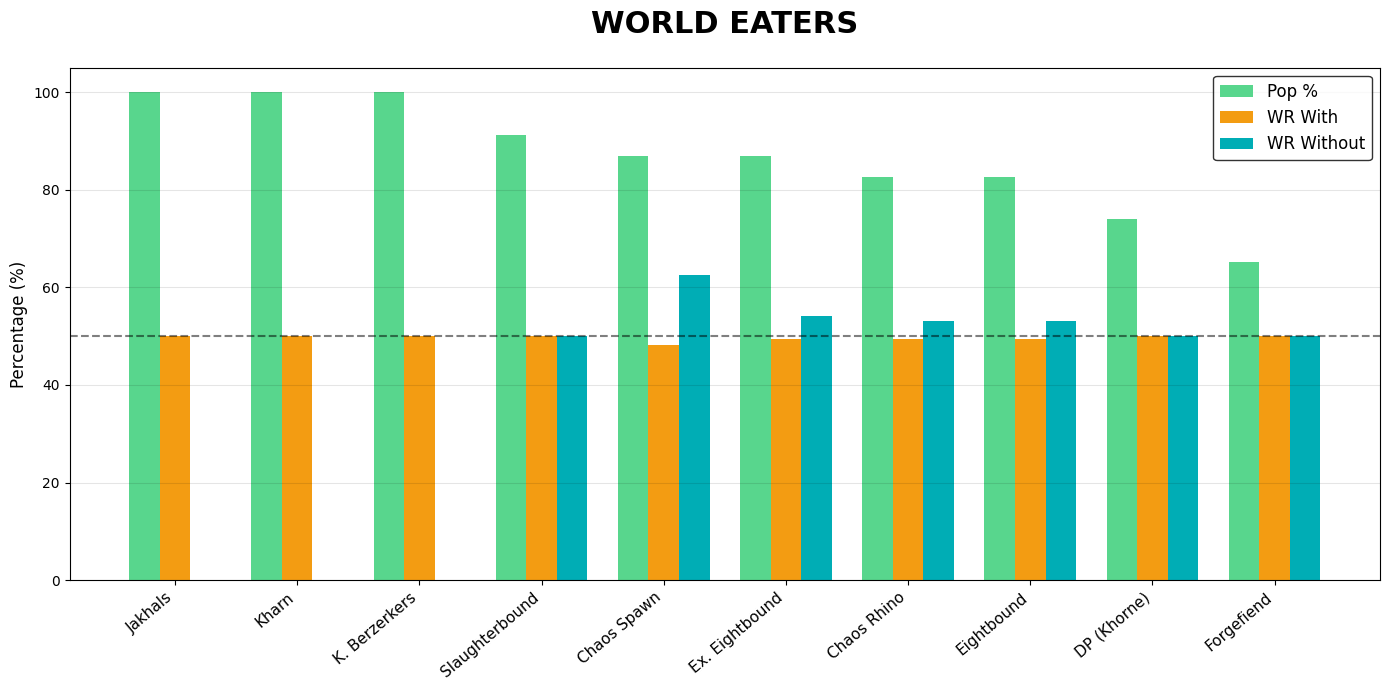

In [42]:
# GRAPH FOR THE POWERPOINT

units = ['Jakhals', 'Kharn', 'K. Berzerkers', 'Slaughterbound', 'Chaos Spawn', 
         'Ex. Eightbound', 'Chaos Rhino', 'Eightbound', 'DP (Khorne)', 'Forgefiend']
pop = [100.0, 100.0, 100.0, 91.3, 87.0, 87.0, 82.6, 82.6, 73.9, 65.2]
wr_with = [50.0, 50.0, 50.0, 50.0, 48.12, 49.38, 49.34, 49.34, 50.0, 50.0]
wr_without = [0, 0, 0, 50.0, 62.50, 54.17, 53.12, 53.12, 50.0, 50.0]

x = np.arange(len(units))
width = 0.25

BG_COLOR = '#ffffff'
TEXT_COLOR = '#000000'

fig, ax = plt.subplots(figsize=(14, 7), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

ax.bar(x - width, pop, width, label='Pop %', color='#58d68d')
ax.bar(x, wr_with, width, label='WR With', color='#f39c12')
ax.bar(x + width, wr_without, width, label='WR Without', color='#00adb5')

ax.set_title('WORLD EATERS', color=TEXT_COLOR, fontsize=22, fontweight='bold', pad=25)
ax.set_xticks(x)
ax.set_xticklabels(units, color=TEXT_COLOR, rotation=40, ha='right', fontsize=11)
ax.tick_params(axis='y', colors=TEXT_COLOR)
ax.set_ylabel('Percentage (%)', color=TEXT_COLOR, fontsize=12)

ax.legend(facecolor=BG_COLOR, edgecolor=TEXT_COLOR, labelcolor=TEXT_COLOR, fontsize=12)
ax.grid(axis='y', color=TEXT_COLOR, alpha=0.1)
ax.axhline(50, color=TEXT_COLOR, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('we_impact_solid.png', dpi=300)
plt.show()

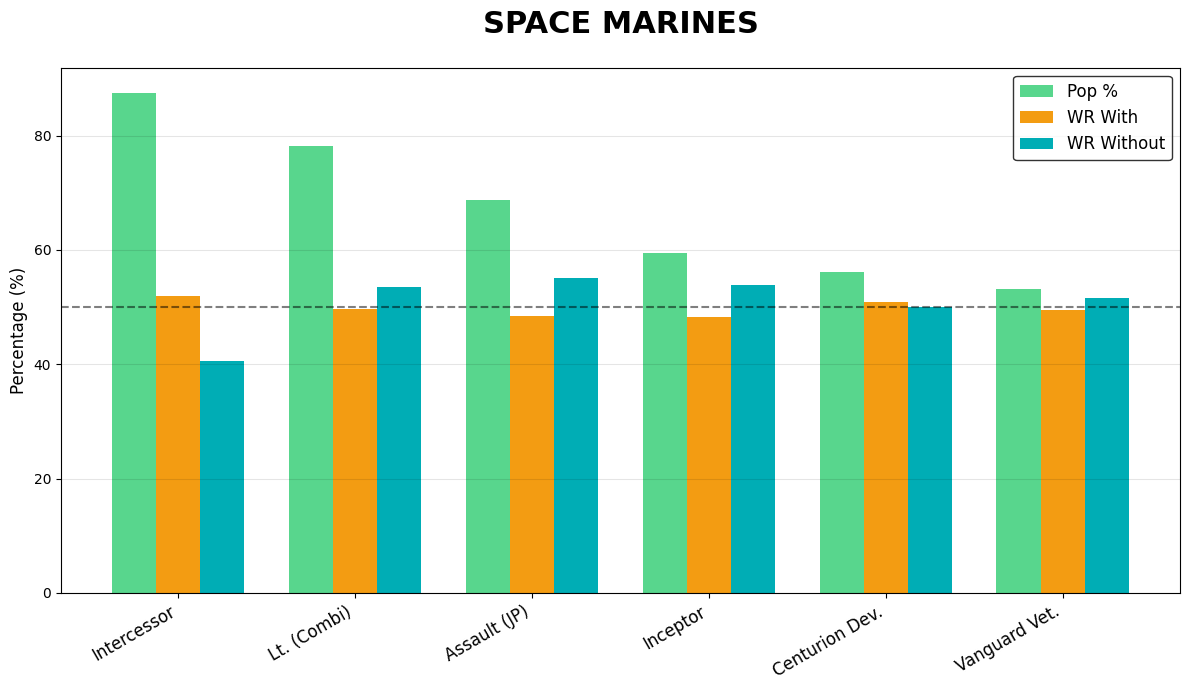

In [43]:
# GRAPH FOR THE POWERPOINT

units_sm = ['Intercessor', 'Lt. (Combi)', 'Assault (JP)', 'Inceptor', 'Centurion Dev.', 'Vanguard Vet.']
pop_sm = [87.5, 78.1, 68.8, 59.4, 56.2, 53.1]
wr_with_sm = [51.91, 49.64, 48.46, 48.21, 50.89, 49.47]
wr_without_sm = [40.62, 53.57, 55.00, 53.85, 50.00, 51.67]

x = np.arange(len(units_sm))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 7), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

ax.bar(x - width, pop_sm, width, label='Pop %', color='#58d68d')
ax.bar(x, wr_with_sm, width, label='WR With', color='#f39c12')
ax.bar(x + width, wr_without_sm, width, label='WR Without', color='#00adb5')

ax.set_title('SPACE MARINES', color=TEXT_COLOR, fontsize=22, fontweight='bold', pad=25)
ax.set_xticks(x)
ax.set_xticklabels(units_sm, color=TEXT_COLOR, rotation=30, ha='right', fontsize=12)
ax.tick_params(axis='y', colors=TEXT_COLOR)
ax.set_ylabel('Percentage (%)', color=TEXT_COLOR, fontsize=12)

ax.legend(facecolor=BG_COLOR, edgecolor=TEXT_COLOR, labelcolor=TEXT_COLOR, fontsize=12)
ax.grid(axis='y', color=TEXT_COLOR, alpha=0.1)
ax.axhline(50, color=TEXT_COLOR, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('sm_impact_solid.png', dpi=300)
plt.show()

### 3.2 Does the player with few units but very high point values win, or the player with many units worth few points?

In this part we would like to understand if winners use few high-point units (quality) or many low points units (quantity)

In [44]:


print("="*36)
print("ARMY COMPOSITION: QUALITY VS QUANTITY")
print("="*36)
print("\nResearch Question: Do elite armies with fewer high-point units")
print("                   outperform swarm armies with many low-point units?")

# STEP 1: PREPARE DATA 
print(f"\n{'-'*80}")
print("STEP 1: Calculate army composition metrics")
print(f"{'-'*80}")

if 'win_rate' not in df_players.columns:
    df_players['total_matches'] = df_players['wins'] + df_players['losses'] + df_players['ties']
    df_players['win_rate'] = (df_players['wins'] / df_players['total_matches'] * 100).fillna(0)

composition_data = []

for player_id in df_players['id_player'].unique():
    player_info = df_players[df_players['id_player'] == player_id].iloc[0]
    army = player_info['army']
    win_rate = player_info['win_rate']
    
    player_units = df_army_list_units[df_army_list_units['id_player'] == player_id]
    
    if len(player_units) == 0:
        continue
    
    total_models = player_units['quantity'].sum()          
    n_unique_units = player_units['clean_name'].nunique()  
    avg_points_per_unit = player_units['points'].mean()     
    
    # Quality ratio: higher = elite (few expensive), lower = swarm (many cheap)
    quality_ratio = avg_points_per_unit / total_models if total_models > 0 else 0
    
    composition_data.append({
        'id_player': player_id,
        'army': army,
        'win_rate': win_rate,
        'total_models': total_models,
        'n_unique_units': n_unique_units,
        'avg_points_per_unit': avg_points_per_unit,
        'quality_ratio': quality_ratio
    })

df_composition = pd.DataFrame(composition_data)

print(f"\nTotal players analyzed: {len(df_composition)}")


ARMY COMPOSITION: QUALITY VS QUANTITY

Research Question: Do elite armies with fewer high-point units
                   outperform swarm armies with many low-point units?

--------------------------------------------------------------------------------
STEP 1: Calculate army composition metrics
--------------------------------------------------------------------------------

Total players analyzed: 402


In [45]:
# STEP 2: ANALYSIS BY FACTION (LOCAL) 

print(f"\n{'-'*80}")
print("STEP 2: Quality vs Quantity by faction (Top 5)")
print(f"{'-'*80}")

top_5_armies = df_composition.groupby('army').size().sort_values(ascending=False).head(5).index.tolist()

print(f"\nAnalyzing top 5 armies:")
for i, army in enumerate(top_5_armies, 1):
    count = len(df_composition[df_composition['army'] == army])
    print(f"  {i}. {army}: {count} players")

strategy_comparison = []

print(f"\n{'Army':<30} {'Strategy':<12} {'N':<6} {'WR (%)':<10} {'Diff':<10} {'P-Val':<10} {'Result':<15}")
print("-" * 100)

for army in top_5_armies:
    subset = df_composition[df_composition['army'] == army].copy()
    
    if len(subset) < 10:
        print(f"{army:<30} Insufficient data (n={len(subset)})")
        continue
    
    # Split by median quality ratio
    median_quality = subset['quality_ratio'].median()
    
    quality_players = subset[subset['quality_ratio'] > median_quality]
    quantity_players = subset[subset['quality_ratio'] <= median_quality]
    
    # T-test
    if len(quality_players) > 0 and len(quantity_players) > 0:
        t_stat, p_value = stats.ttest_ind(
            quality_players['win_rate'], 
            quantity_players['win_rate'], 
            equal_var=False
        )
        
        wr_quality = quality_players['win_rate'].mean()
        wr_quantity = quantity_players['win_rate'].mean()
        diff = wr_quality - wr_quantity
        
        significant = p_value < 0.05
        
        # Determine winner
        if significant:
            if diff > 0:
                winner = 'QUALITY'
            else:
                winner = 'QUANTITY'
        else:
            winner = 'TIE'
        
        # Print results
        print(f"{army:<30} {'QUALITY':<12} {len(quality_players):<6} {wr_quality:>8.2f}%")
        print(f"{'':<30} {'QUANTITY':<12} {len(quantity_players):<6} {wr_quantity:>8.2f}% {diff:>+9.2f}% {p_value:>9.4f} {winner:<15}")
        print("-" * 100)
        
        # Effect size (Cohen's d)
        pooled_std = np.sqrt((quality_players['win_rate'].std()**2 + 
                              quantity_players['win_rate'].std()**2) / 2)
        cohens_d = diff / pooled_std if pooled_std > 0 else 0
        
        if abs(cohens_d) > 0.8:
            effect_size = "LARGE"
        elif abs(cohens_d) > 0.5:
            effect_size = "MEDIUM"
        elif abs(cohens_d) > 0.2:
            effect_size = "SMALL"
        else:
            effect_size = "NEGLIGIBLE"
        
        strategy_comparison.append({
            'Army': army,
            'Quality N': len(quality_players),
            'Quantity N': len(quantity_players),
            'Quality WR (%)': wr_quality,
            'Quantity WR (%)': wr_quantity,
            'Difference (%)': diff,
            'P-Value': p_value,
            'Cohens d': cohens_d,
            'Effect Size': effect_size,
            'Significant': 'YES' if significant else 'NO',
            'Winner': winner
        })

df_strategy = pd.DataFrame(strategy_comparison)


--------------------------------------------------------------------------------
STEP 2: Quality vs Quantity by faction (Top 5)
--------------------------------------------------------------------------------

Analyzing top 5 armies:
  1. space marines (astartes): 32 players
  2. aeldari: 31 players
  3. adeptus mechanicus: 28 players
  4. world eaters: 23 players
  5. death guard: 23 players

Army                           Strategy     N      WR (%)     Diff       P-Val      Result         
----------------------------------------------------------------------------------------------------
space marines (astartes)       QUALITY      16        50.00%
                               QUANTITY     16        51.00%     -1.00%    0.8451 TIE            
----------------------------------------------------------------------------------------------------
aeldari                        QUALITY      15        60.83%
                               QUANTITY     16        45.98%    +14.85%    0.023

In [46]:
#  STEP 3: GLOBAL ANALYSIS

print(f"\n{'-'*80}")
print("STEP 3: Quality vs Quantity - Global analysis")
print(f"{'-'*80}")

# Global median
global_median = df_composition['quality_ratio'].median()

quality_global = df_composition[df_composition['quality_ratio'] > global_median]
quantity_global = df_composition[df_composition['quality_ratio'] <= global_median]

t_stat_global, p_value_global = stats.ttest_ind(
    quality_global['win_rate'],
    quantity_global['win_rate'],
    equal_var=False
)

wr_quality_global = quality_global['win_rate'].mean()
wr_quantity_global = quantity_global['win_rate'].mean()
diff_global = wr_quality_global - wr_quantity_global

pooled_std_global = np.sqrt((quality_global['win_rate'].std()**2 + 
                             quantity_global['win_rate'].std()**2) / 2)
cohens_d_global = diff_global / pooled_std_global if pooled_std_global > 0 else 0

print(f"\nGlobal comparison (all factions):")
print(f"  QUALITY players: n={len(quality_global)}, WR={wr_quality_global:.2f}%")
print(f"  QUANTITY players: n={len(quantity_global)}, WR={wr_quantity_global:.2f}%")
print(f"  Difference: {diff_global:+.2f}%")
print(f"  P-value: {p_value_global:.6f} {'[SIGNIFICANT]' if p_value_global < 0.05 else '[Not significant]'}")
print(f"  Cohen's d: {cohens_d_global:.4f}")


--------------------------------------------------------------------------------
STEP 3: Quality vs Quantity - Global analysis
--------------------------------------------------------------------------------

Global comparison (all factions):
  QUALITY players: n=201, WR=48.03%
  QUANTITY players: n=201, WR=50.66%
  Difference: -2.63%
  P-value: 0.143979 [Not significant]
  Cohen's d: -0.1460



--------------------------------------------------------------------------------
STEP 4: Generating visualizations
--------------------------------------------------------------------------------


/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/1397580545.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=box_data, x='Strategy', y='Win Rate', ax=axes[idx], palette='Set2')
/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/1397580545.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=box_data, x='Strategy', y='Win Rate', ax=axes[idx], palette='Set2')
/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/1397580545.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=box_data, x=

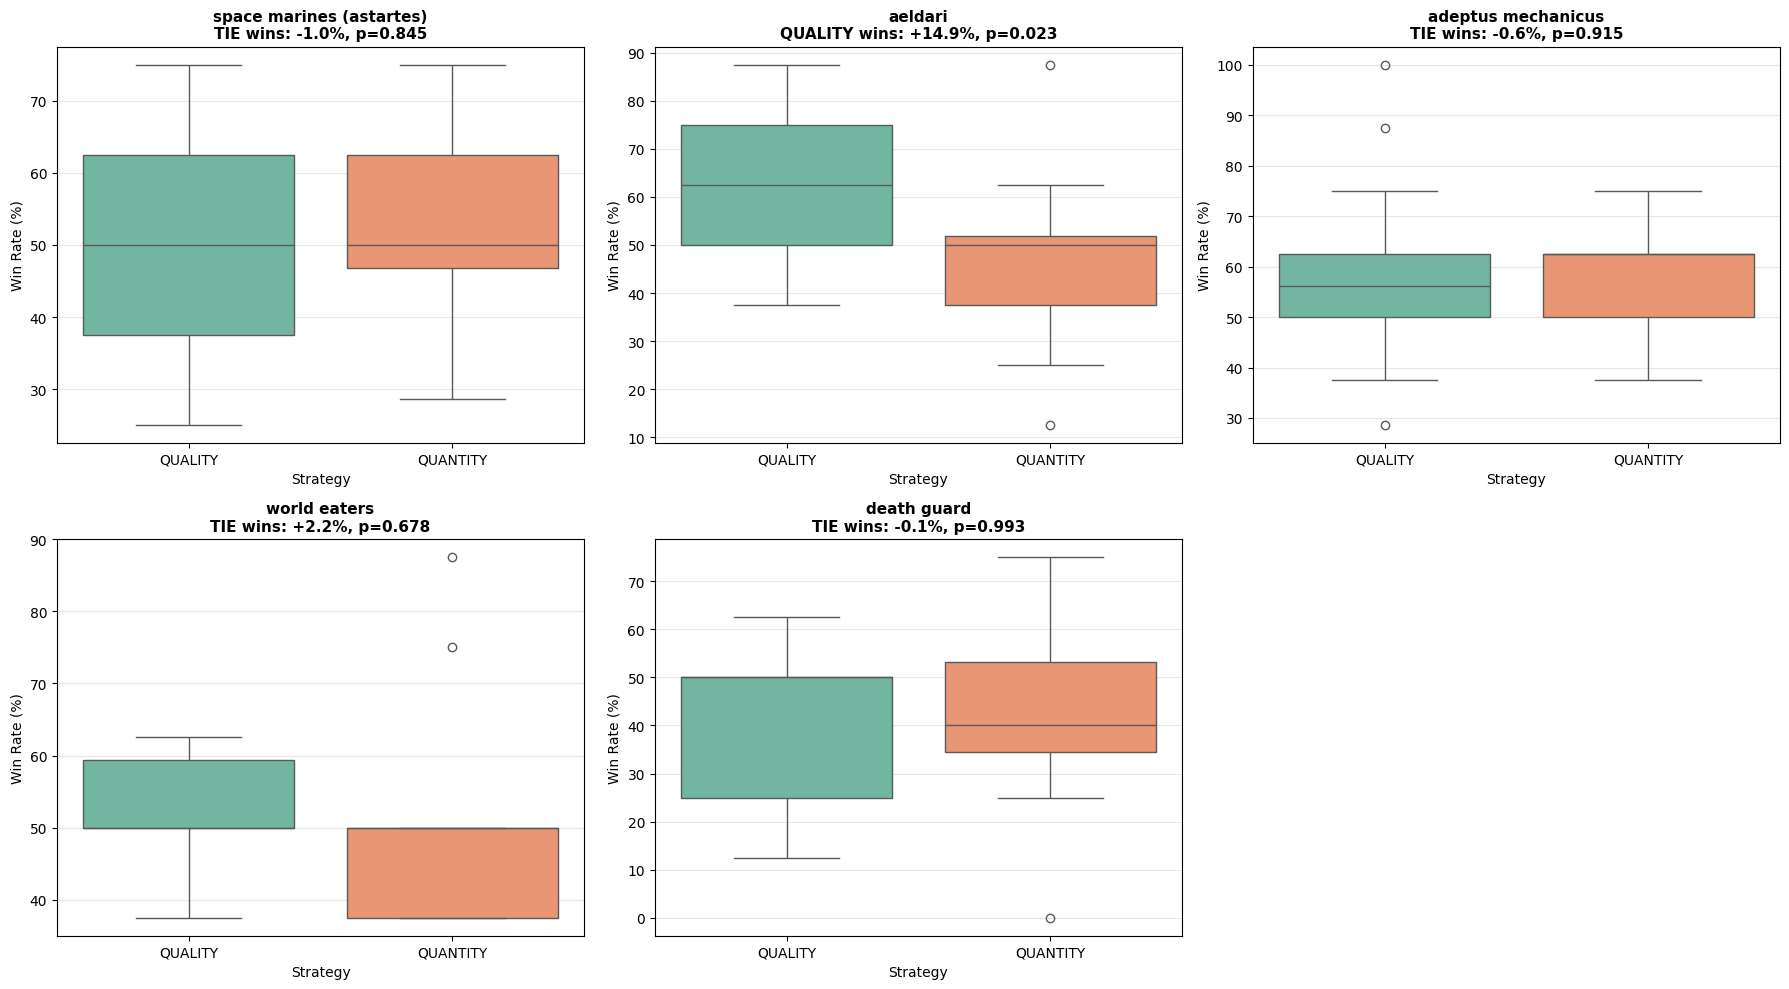

In [47]:
# STEP 4: VISUALIZATIONS

print(f"\n{'-'*80}")
print("STEP 4: Generating visualizations")
print(f"{'-'*80}")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, army in enumerate(top_5_armies):
    subset = df_composition[df_composition['army'] == army]
    
    if len(subset) < 10:
        axes[idx].text(0.5, 0.5, f'{army}\nInsufficient data', 
                      ha='center', va='center', fontsize=12)
        axes[idx].set_xlim(0, 1)
        axes[idx].set_ylim(0, 1)
        continue
    
    median_q = subset['quality_ratio'].median()
    
    quality = subset[subset['quality_ratio'] > median_q]
    quantity = subset[subset['quality_ratio'] <= median_q]
    
    box_data = pd.DataFrame({
        'Strategy': ['QUALITY'] * len(quality) + ['QUANTITY'] * len(quantity),
        'Win Rate': pd.concat([quality['win_rate'], quantity['win_rate']])
    })
    
    sns.boxplot(data=box_data, x='Strategy', y='Win Rate', ax=axes[idx], palette='Set2')
    
    result_row = df_strategy[df_strategy['Army'] == army]
    if len(result_row) > 0:
        winner = result_row.iloc[0]['Winner']
        diff = result_row.iloc[0]['Difference (%)']
        p_val = result_row.iloc[0]['P-Value']
        
        axes[idx].set_title(f'{army}\n{winner} wins: {diff:+.1f}%, p={p_val:.3f}',
                           fontsize=11, fontweight='bold')
    else:
        axes[idx].set_title(f'{army}', fontsize=11, fontweight='bold')
    
    axes[idx].set_ylabel('Win Rate (%)', fontsize=10)
    axes[idx].grid(axis='y', alpha=0.3)

if len(top_5_armies) < 6:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


In [48]:
# FINAL SUMMARY 
print(f"\n{'='*35}")
print("FINAL SUMMARY: QUALITY VS QUANTITY")
print(f"{'='*35}")

if len(df_strategy) > 0:
    print("\nRESULTS BY FACTION:")
    print(df_strategy[['Army', 'Difference (%)', 'P-Value', 'Effect Size', 'Winner']].to_string(index=False))
    
    n_quality = sum(df_strategy['Winner'] == 'QUALITY')
    n_quantity = sum(df_strategy['Winner'] == 'QUANTITY')
    n_tie = sum(df_strategy['Winner'] == 'TIE')
    
    print(f"\nSUMMARY (Local - by faction):")
    print(f"  Factions where QUALITY wins: {n_quality}/{len(df_strategy)}")
    print(f"  Factions where QUANTITY wins: {n_quantity}/{len(df_strategy)}")
    print(f"  Factions with no clear winner: {n_tie}/{len(df_strategy)}")

print(f"\nSUMMARY (Global - all factions):")
print(f"  Difference: {diff_global:+.2f}%")
print(f"  P-value: {p_value_global:.4f}")
print(f"  Effect size: Cohen's d = {cohens_d_global:.4f}")

if p_value_global < 0.05:
    if diff_global > 0:
        print(f"\n  GLOBAL CONCLUSION: QUALITY strategy wins (+{diff_global:.2f}% WR)")
    else:
        print(f"\n  GLOBAL CONCLUSION: QUANTITY strategy wins (+{abs(diff_global):.2f}% WR)")
else:
    print(f"\n  GLOBAL CONCLUSION: No significant global trend")


FINAL SUMMARY: QUALITY VS QUANTITY

RESULTS BY FACTION:
                    Army  Difference (%)  P-Value Effect Size  Winner
space marines (astartes)       -1.004464 0.845093  NEGLIGIBLE     TIE
                 aeldari       14.851190 0.023266       LARGE QUALITY
      adeptus mechanicus       -0.637755 0.915107  NEGLIGIBLE     TIE
            world eaters        2.211538 0.677539  NEGLIGIBLE     TIE
             death guard       -0.067641 0.993123  NEGLIGIBLE     TIE

SUMMARY (Local - by faction):
  Factions where QUALITY wins: 1/5
  Factions where QUANTITY wins: 0/5
  Factions with no clear winner: 4/5

SUMMARY (Global - all factions):
  Difference: -2.63%
  P-value: 0.1440
  Effect size: Cohen's d = -0.1460

  GLOBAL CONCLUSION: No significant global trend


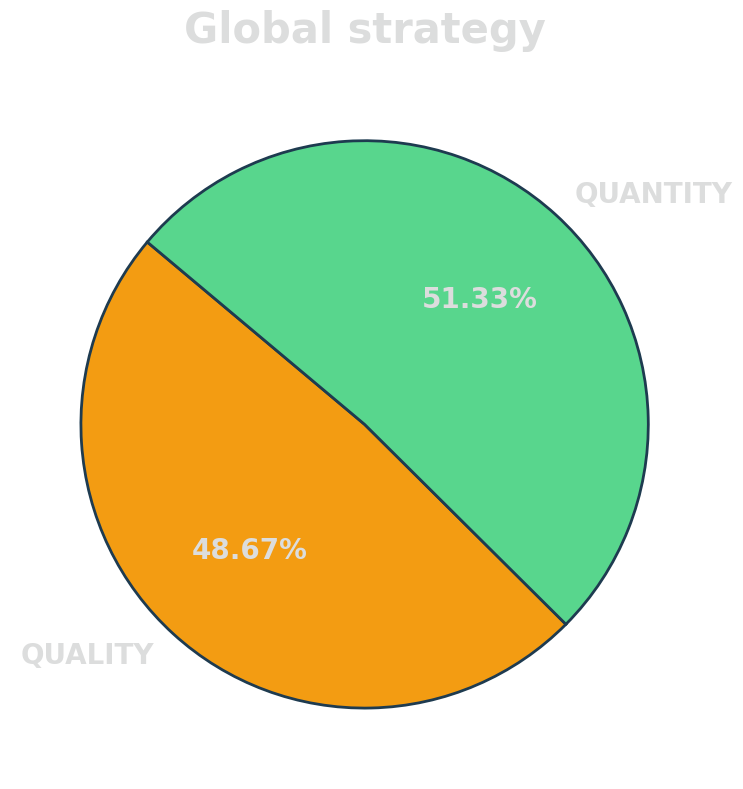

In [49]:
# CAKE GRAPH FOR PRESENTATION

labels = ['QUALITY', 'QUANTITY']
sizes = [48.03, 50.66]
colors = ['#f39c12', '#58d68d'] 
TEXT_COLOR = '#dcdddd' 

fig, ax = plt.subplots(figsize=(8, 8))
fig.patch.set_alpha(0) 
ax.set_facecolor("none") 


patches, texts, autotexts = ax.pie(
    sizes, 
    labels=labels, 
    autopct='%1.2f%%', 
    startangle=140, 
    colors=colors,
    textprops={'color': TEXT_COLOR, 'fontsize': 20, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': '#1e3b50', 'linewidth': 2} 
)

plt.title('Global strategy', color=TEXT_COLOR, fontsize=30, pad=20, fontweight='bold')

plt.tight_layout()

plt.savefig('global_strategy_pie.png', transparent=True, dpi=300)
plt.show()

## 4.There is a dynamic where there is a specific win rate between factions?

Ex: Space marines wins against eldar, but lose against necrons

In [50]:
# MATCHUP ANALYSIS: WHO BEATS WHO?

print("="*32)
print("MATCHUP ANALYSIS: WHO BEATS WHO?")
print("="*32)

player_to_army = df_players.set_index('id_player')['army'].to_dict()

df_m = df_matches.copy()
df_m['army1'] = df_m['id_player1'].map(player_to_army)
df_m['army2'] = df_m['id_player2'].map(player_to_army)

df_m = df_m.dropna(subset=['army1', 'army2'])

print(f"Total matches analyzed: {len(df_m)}")

def get_winner(row):
    if row['score_player1'] > row['score_player2']:
        return 1 
    elif row['score_player1'] < row['score_player2']:
        return 2 
    else:
        return 0  

df_m['winner'] = df_m.apply(get_winner, axis=1)


MATCHUP ANALYSIS: WHO BEATS WHO?
Total matches analyzed: 1603


In [51]:
# MATCHUP ANALYSIS: PAIRWISE

print(f"\n{'-'*80}")
print("Matchup analysis (pairwise)")
print(f"{'-'*80}")

MIN_MATCHES = 5
top_armies = df_players.groupby('army').size().sort_values(ascending=False).head(10).index.tolist()

print(f"\nAnalyzing top {len(top_armies)} armies:")
for i, army in enumerate(top_armies, 1):
    count = len(df_players[df_players['army'] == army])
    print(f"  {i}. {army}: {count} players")

matchup_data = []

for i, army_a in enumerate(top_armies):
    for army_b in top_armies[i+1:]:  
        m1 = df_m[(df_m['army1'] == army_a) & (df_m['army2'] == army_b)]
        m2 = df_m[(df_m['army1'] == army_b) & (df_m['army2'] == army_a)]
        
        wins_a = len(m1[m1['winner'] == 1]) + len(m2[m2['winner'] == 2])
        wins_b = len(m1[m1['winner'] == 2]) + len(m2[m2['winner'] == 1])
        draws = len(m1[m1['winner'] == 0]) + len(m2[m2['winner'] == 0])
        total = wins_a + wins_b + draws
        
        if total >= MIN_MATCHES:
            wr_a = (wins_a / (wins_a + wins_b)) * 100 if (wins_a + wins_b) > 0 else 50

            p_val = binomtest(wins_a, n=(wins_a + wins_b), p=0.5, alternative='two-sided').pvalue
            
            significant = p_val < 0.05
            
            matchup_data.append({
                'Faction A': army_a,
                'Faction B': army_b,
                'Total Matches': total,
                'Wins A': wins_a,
                'Wins B': wins_b,
                'Draws': draws,
                'WR A vs B (%)': wr_a,
                'P-Value': p_val,
                'Significant': 'YES' if significant else 'NO',
                'Favors': army_a if (wr_a > 50 and significant) else army_b if (wr_a < 50 and significant) else 'BALANCED'
            })

df_matchups = pd.DataFrame(matchup_data).sort_values('P-Value')

print(f"\nTotal matchups analyzed: {len(df_matchups)}")
print(f"Significant matchups (p < 0.05): {sum(df_matchups['Significant'] == 'YES')}")



--------------------------------------------------------------------------------
Matchup analysis (pairwise)
--------------------------------------------------------------------------------

Analyzing top 10 armies:
  1. space marines (astartes): 32 players
  2. aeldari: 31 players
  3. adeptus mechanicus: 28 players
  4. world eaters: 23 players
  5. death guard: 23 players
  6. imperial knights: 20 players
  7. necrons: 18 players
  8. chaos space marines: 16 players
  9. t'au empire: 16 players
  10. adepta sororitas: 16 players

Total matchups analyzed: 40
Significant matchups (p < 0.05): 3


In [52]:
# MOST UNBALANCED MATCHUPS

print(f"\n{'-'*80}")
print("Most unbalanced matchups")
print(f"{'-'*80}")

print("\nTOP 15 MOST UNBALANCED MATCHUPS (by p-value):")
print(f"\n{'Faction A':<30} {'vs':<5} {'Faction B':<30} {'WR A (%)':<10} {'Matches':<10} {'P-Value':<12} {'Sig':<5}")
print("-" * 110)

for _, row in df_matchups.head(10).iterrows():
    sig_marker = "SIG" if row['Significant'] == 'YES' else "-"
    favors = " [FAVORS A]" if row['Favors'] == row['Faction A'] else " [FAVORS B]" if row['Favors'] == row['Faction B'] else ""
    print(f"{row['Faction A']:<30} {'vs':<5} {row['Faction B']:<30} {row['WR A vs B (%)']:>8.1f}% {row['Total Matches']:>9} {row['P-Value']:>11.4f} {sig_marker:<5}{favors}")



--------------------------------------------------------------------------------
Most unbalanced matchups
--------------------------------------------------------------------------------

TOP 15 MOST UNBALANCED MATCHUPS (by p-value):

Faction A                      vs    Faction B                      WR A (%)   Matches    P-Value      Sig  
--------------------------------------------------------------------------------------------------------------
space marines (astartes)       vs    imperial knights                   85.7%        14      0.0129 SIG   [FAVORS A]
necrons                        vs    chaos space marines               100.0%         7      0.0156 SIG   [FAVORS A]
death guard                    vs    necrons                             0.0%         6      0.0312 SIG   [FAVORS B]
adeptus mechanicus             vs    t'au empire                        87.5%         8      0.0703 -    
death guard                    vs    adepta sororitas                   20.0%        10

In [53]:
# MATCHUP MATRIX CREATION

print(f"\n{'-'*80}")
print("Creating matchup matrix")
print(f"{'-'*80}")

matrix_data = []

for _, row in df_matchups.iterrows():
    matrix_data.append({
        'Attacker': row['Faction A'],
        'Defender': row['Faction B'],
        'Win Rate (%)': row['WR A vs B (%)'],
        'Matches': row['Total Matches']
    })
    
    matrix_data.append({
        'Attacker': row['Faction B'],
        'Defender': row['Faction A'],
        'Win Rate (%)': 100 - row['WR A vs B (%)'],
        'Matches': row['Total Matches']
    })

df_matrix = pd.DataFrame(matrix_data)

pivot_wr = df_matrix.pivot_table(index='Attacker', columns='Defender', values='Win Rate (%)', aggfunc='mean')
pivot_matches = df_matrix.pivot_table(index='Attacker', columns='Defender', values='Matches', aggfunc='mean')

for army in pivot_wr.index:
    if army in pivot_wr.columns:
        pivot_wr.loc[army, army] = np.nan

print(f"\nMatchup matrix created: {pivot_wr.shape[0]} x {pivot_wr.shape[1]}")



--------------------------------------------------------------------------------
Creating matchup matrix
--------------------------------------------------------------------------------

Matchup matrix created: 10 x 10


In [54]:
# NEMESIS AND PREY IDENTIFICATION

print(f"\n{'-'*80}")
print("Nemesis and prey identification")
print(f"{'-'*80}")

nemesis_summary = []

for army in top_armies:
    as_attacker = df_matchups[df_matchups['Faction A'] == army].copy()
    as_defender = df_matchups[df_matchups['Faction B'] == army].copy()
    
    as_attacker['Opponent'] = as_attacker['Faction B']
    as_attacker['WR'] = as_attacker['WR A vs B (%)']
    
    as_defender['Opponent'] = as_defender['Faction A']
    as_defender['WR'] = 100 - as_defender['WR A vs B (%)']
    
    all_matchups = pd.concat([
        as_attacker[['Opponent', 'WR', 'P-Value', 'Total Matches', 'Significant']],
        as_defender[['Opponent', 'WR', 'P-Value', 'Total Matches', 'Significant']]
    ])
    
    if len(all_matchups) == 0:
        continue
    
    best = all_matchups.sort_values('WR', ascending=False).iloc[0]
    worst = all_matchups.sort_values('WR', ascending=True).iloc[0]
    
    
    nemesis_summary.append({
        'Faction': army,
        'Best Matchup (PREY)': best['Opponent'],
        'WR vs Prey (%)': best['WR'],
        'Prey Sig': 'SIG' if best['Significant'] == 'YES' else '-',
        'Worst Matchup (NEMESIS)': worst['Opponent'],
        'WR vs Nemesis (%)': worst['WR'],
        'Nemesis Sig': 'SIG' if worst['Significant'] == 'YES' else '-',
    })

df_nemesis = pd.DataFrame(nemesis_summary)

print("\nNEMESIS AND PREY TABLE:")
print(f"\n{'Faction':<30} {'Best vs (PREY)':<33} {'WR':<10} {'Worst vs (NEMESIS)':<33} {'WR':<10}")
print("-" * 120)

for _, row in df_nemesis.iterrows():
    prey_marker = f" [{row['Prey Sig']}]" if row['Prey Sig'] == 'SIG' else ""
    nemesis_marker = f" [{row['Nemesis Sig']}]" if row['Nemesis Sig'] == 'SIG' else ""
    
    print(f"{row['Faction']:<30} {row['Best Matchup (PREY)']:<30} {row['WR vs Prey (%)']:>6.1f}%{prey_marker:<6} "
          f"{row['Worst Matchup (NEMESIS)']:<30} {row['WR vs Nemesis (%)']:>6.1f}%{nemesis_marker:<6}")



--------------------------------------------------------------------------------
Nemesis and prey identification
--------------------------------------------------------------------------------

NEMESIS AND PREY TABLE:

Faction                        Best vs (PREY)                    WR         Worst vs (NEMESIS)                WR        
------------------------------------------------------------------------------------------------------------------------
space marines (astartes)       imperial knights                 85.7% [SIG] adeptus mechanicus               38.9%      
aeldari                        death guard                      80.0%       chaos space marines              28.6%      
adeptus mechanicus             t'au empire                      87.5%       chaos space marines              54.5%      
world eaters                   necrons                          83.3%       adeptus mechanicus               31.2%      
death guard                    imperial knights      

/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/3579225338.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  annotations.loc[i, j] = ""
/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/3579225338.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '45%
(n=11)' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  annotations.loc[i, j] = f"{pivot_wr.loc[i, j]:.0f}%\n(n={int(pivot_matches.loc[i, j])})"
/var/folders/5v/4kft3jsj3m55jwb7mr5cdwyr0000gn/T/ipykernel_9648/3579225338.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '33%
(n=10)' has dtype incompatible with float64, please e

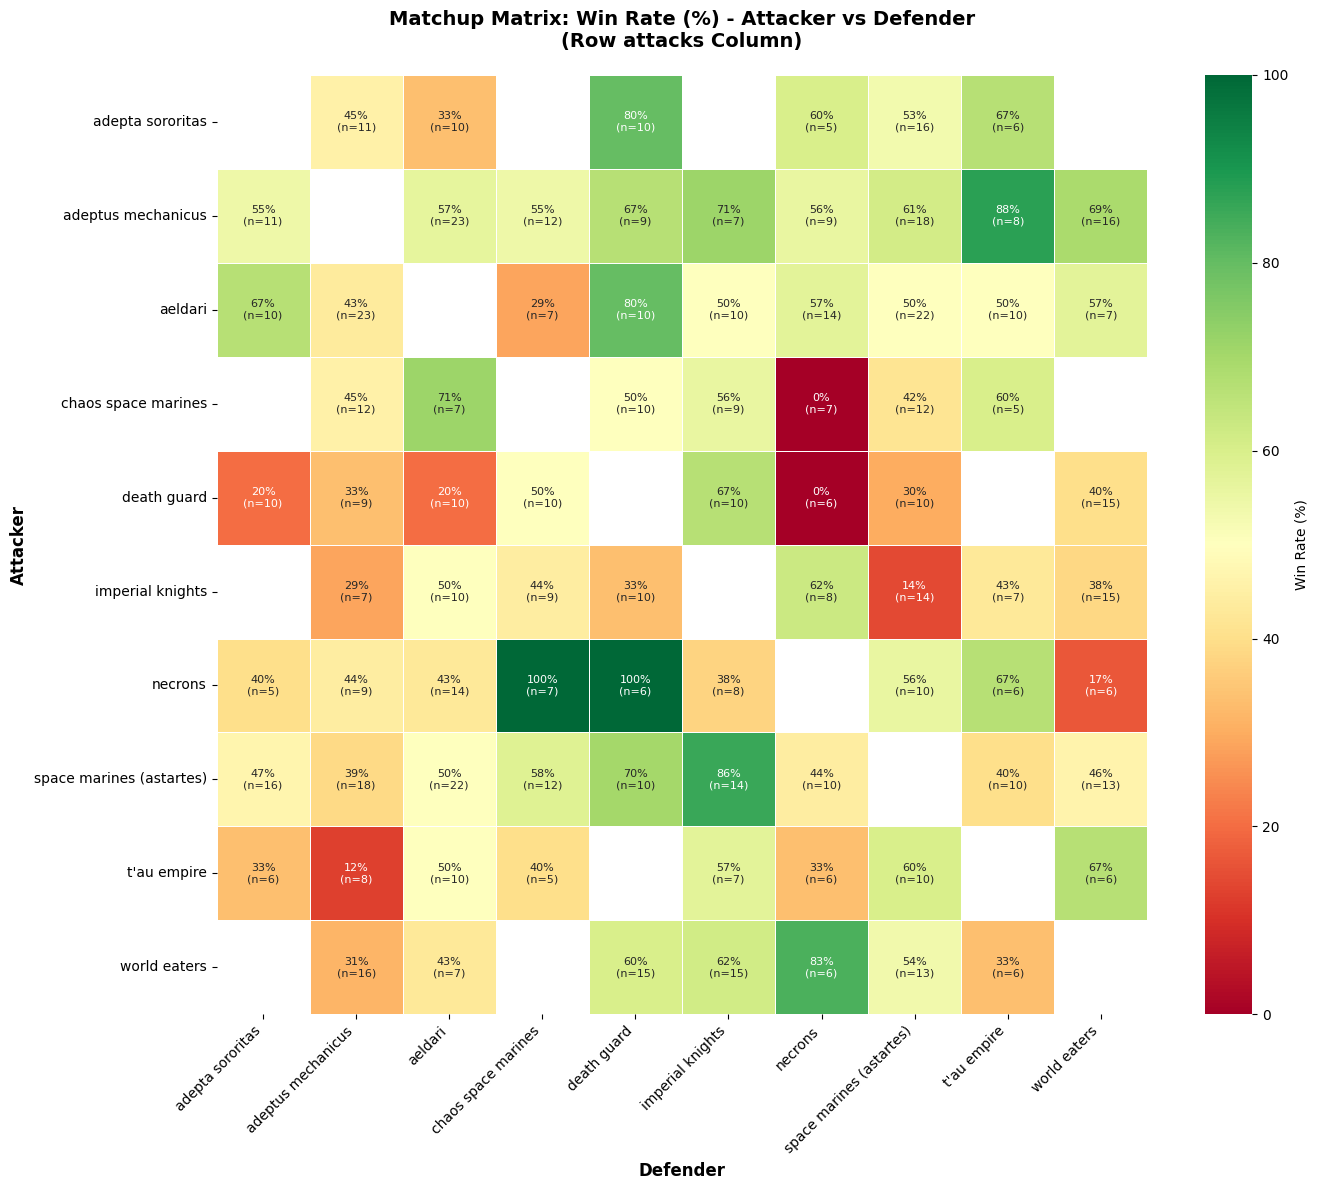

In [55]:
# MATCHUP MATRIX OUTPUT

fig, ax = plt.subplots(figsize=(14, 12))

annotations = pivot_matches.copy()
for i in pivot_wr.index:
    for j in pivot_wr.columns:
        if pd.notna(pivot_wr.loc[i, j]):
            annotations.loc[i, j] = f"{pivot_wr.loc[i, j]:.0f}%\n(n={int(pivot_matches.loc[i, j])})"
        else:
            annotations.loc[i, j] = ""

sns.heatmap(pivot_wr, annot=annotations, fmt='', cmap='RdYlGn', center=50, 
            vmin=0, vmax=100, cbar_kws={'label': 'Win Rate (%)'}, 
            linewidths=0.5, ax=ax, annot_kws={'fontsize': 8})

ax.set_title('Matchup Matrix: Win Rate (%) - Attacker vs Defender\n(Row attacks Column)', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Defender', fontsize=12, fontweight='bold')
ax.set_ylabel('Attacker', fontsize=12, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [56]:
# MATCHUP ANALYSIS: FINAL SUMMARY

print(f"\n{'='*80}")
print("FINAL SUMMARY")
print(f"{'='*80}")

n_significant = sum(df_matchups['Significant'] == 'YES')
n_total = len(df_matchups)

print(f"\n1. MATCHUP DYNAMICS:")
print(f"   Total matchups analyzed: {n_total}")
print(f"   Significant matchups: {n_significant} ({n_significant/n_total*100:.1f}%)")

if n_significant > 0:
    print(f"\n   YES - There ARE faction-specific matchup dynamics")
    print(f"   Some factions have clear advantages/disadvantages against specific opponents")
else:
    print(f"\n   NO - No clear matchup dynamics detected")
    print(f"   All matchups appear relatively balanced")

print(f"\n2. MOST POLARIZED MATCHUPS:")
most_polarized = df_matchups[df_matchups['Significant'] == 'YES'].copy()
most_polarized['Polarization'] = abs(most_polarized['WR A vs B (%)'] - 50)
most_polarized = most_polarized.sort_values('Polarization', ascending=False).head(3)

if len(most_polarized) > 0:
    for _, row in most_polarized.iterrows():
        winner = row['Faction A'] if row['WR A vs B (%)'] > 50 else row['Faction B']
        loser = row['Faction B'] if row['WR A vs B (%)'] > 50 else row['Faction A']
        wr = max(row['WR A vs B (%)'], 100 - row['WR A vs B (%)'])
        print(f"   - {winner} dominates {loser} ({wr:.1f}% WR, n={row['Total Matches']})")
else:
    print(f"   None found")

print(f"\n3. MOST BALANCED MATCHUPS:")
most_balanced = df_matchups.copy()
most_balanced['Balance'] = abs(most_balanced['WR A vs B (%)'] - 50)
most_balanced = most_balanced[most_balanced['Total Matches'] >= 10].sort_values('Balance').head(3)

if len(most_balanced) > 0:
    for _, row in most_balanced.iterrows():
        print(f"   - {row['Faction A']} vs {row['Faction B']} ({row['WR A vs B (%)']:.1f}% WR, n={row['Total Matches']})")
else:
    print(f"   None found")


FINAL SUMMARY

1. MATCHUP DYNAMICS:
   Total matchups analyzed: 40
   Significant matchups: 3 (7.5%)

   YES - There ARE faction-specific matchup dynamics
   Some factions have clear advantages/disadvantages against specific opponents

2. MOST POLARIZED MATCHUPS:
   - necrons dominates chaos space marines (100.0% WR, n=7)
   - necrons dominates death guard (100.0% WR, n=6)
   - space marines (astartes) dominates imperial knights (85.7% WR, n=14)

3. MOST BALANCED MATCHUPS:
   - space marines (astartes) vs aeldari (50.0% WR, n=22)
   - aeldari vs t'au empire (50.0% WR, n=10)
   - aeldari vs imperial knights (50.0% WR, n=10)
